## 0. Libraries and Dataset preparation

In [41]:
# Import libraries
import pandas as pd
import numpy as np
import re
import random as rnd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import KNNImputer
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
import optuna
from scipy.stats import uniform


from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam
from keras.optimizers import RMSprop
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import make_scorer, mean_squared_error, r2_score


In [2]:
# Load data
file_path = '/Users/jane/Desktop/Python and Advanced Data Science/vehicles.csv'
df_car = pd.read_csv(file_path)
df_car.head(10)

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,prescott,https://prescott.craigslist.org,6000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,fayetteville,https://fayar.craigslist.org,11900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,florida keys,https://keys.craigslist.org,21000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,worcester / central MA,https://worcester.craigslist.org,1500,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,greensboro,https://greensboro.craigslist.org,4900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN,NaN,NaN
5,7222379453,https://hudsonvalley.craigslist.org/cto/d/west...,hudson valley,https://hudsonvalley.craigslist.org,1600,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ny,NaN,NaN,NaN
6,7221952215,https://hudsonvalley.craigslist.org/cto/d/west...,hudson valley,https://hudsonvalley.craigslist.org,1000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ny,NaN,NaN,NaN
7,7220195662,https://hudsonvalley.craigslist.org/cto/d/poug...,hudson valley,https://hudsonvalley.craigslist.org,15995,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ny,NaN,NaN,NaN
8,7209064557,https://medford.craigslist.org/cto/d/grants-pa...,medford-ashland,https://medford.craigslist.org,5000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,or,NaN,NaN,NaN
9,7219485069,https://erie.craigslist.org/cto/d/erie-2012-su...,erie,https://erie.craigslist.org,3000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,pa,NaN,NaN,NaN


In [3]:
# Check the columns
df_car = df_car.loc[:, ~df_car.columns.str.contains('^Unnamed')]
df_car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  object 
 2   region        426880 non-null  object 
 3   region_url    426880 non-null  object 
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  object 
 7   model         421603 non-null  object 
 8   condition     252776 non-null  object 
 9   cylinders     249202 non-null  object 
 10  fuel          423867 non-null  object 
 11  odometer      422480 non-null  float64
 12  title_status  418638 non-null  object 
 13  transmission  424324 non-null  object 
 14  VIN           265838 non-null  object 
 15  drive         296313 non-null  object 
 16  size          120519 non-null  object 
 17  type          334022 non-null  object 
 18  pain

## 1. Data cleaning and preparation

#### 1.1 Check Data Quality

In [4]:
# Check the duplicated rows
df_car.duplicated()
df_car.drop_duplicates()
# df_car.info()
# The results show that there are no repeatative rows

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,prescott,https://prescott.craigslist.org,6000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,fayetteville,https://fayar.craigslist.org,11900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,florida keys,https://keys.craigslist.org,21000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,worcester / central MA,https://worcester.craigslist.org,1500,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,greensboro,https://greensboro.craigslist.org,4900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
426875,7301591192,https://wyoming.craigslist.org/ctd/d/atlanta-2...,wyoming,https://wyoming.craigslist.org,23590,2019.0,nissan,maxima s sedan 4d,good,6 cylinders,...,NaN,sedan,NaN,https://images.craigslist.org/00o0o_iiraFnHg8q...,Carvana is the safer way to buy a car During t...,NaN,wy,33.786500,-84.445400,2021-04-04T03:21:31-0600
426876,7301591187,https://wyoming.craigslist.org/ctd/d/atlanta-2...,wyoming,https://wyoming.craigslist.org,30590,2020.0,volvo,s60 t5 momentum sedan 4d,good,NaN,...,NaN,sedan,red,https://images.craigslist.org/00x0x_15sbgnxCIS...,Carvana is the safer way to buy a car During t...,NaN,wy,33.786500,-84.445400,2021-04-04T03:21:29-0600
426877,7301591147,https://wyoming.craigslist.org/ctd/d/atlanta-2...,wyoming,https://wyoming.craigslist.org,34990,2020.0,cadillac,xt4 sport suv 4d,good,NaN,...,NaN,hatchback,white,https://images.craigslist.org/00L0L_farM7bxnxR...,Carvana is the safer way to buy a car During t...,NaN,wy,33.779214,-84.411811,2021-04-04T03:21:17-0600
426878,7301591140,https://wyoming.craigslist.org/ctd/d/atlanta-2...,wyoming,https://wyoming.craigslist.org,28990,2018.0,lexus,es 350 sedan 4d,good,6 cylinders,...,NaN,sedan,silver,https://images.craigslist.org/00z0z_bKnIVGLkDT...,Carvana is the safer way to buy a car During t...,NaN,wy,33.786500,-84.445400,2021-04-04T03:21:11-0600


In [5]:
# Remove unwanted columns
df_car=df_car.drop(columns=['id','url','region_url','VIN','image_url','description', 'county'])
df_car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 19 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   region        426880 non-null  object 
 1   price         426880 non-null  int64  
 2   year          425675 non-null  float64
 3   manufacturer  409234 non-null  object 
 4   model         421603 non-null  object 
 5   condition     252776 non-null  object 
 6   cylinders     249202 non-null  object 
 7   fuel          423867 non-null  object 
 8   odometer      422480 non-null  float64
 9   title_status  418638 non-null  object 
 10  transmission  424324 non-null  object 
 11  drive         296313 non-null  object 
 12  size          120519 non-null  object 
 13  type          334022 non-null  object 
 14  paint_color   296677 non-null  object 
 15  state         426880 non-null  object 
 16  lat           420331 non-null  float64
 17  long          420331 non-null  float64
 18  post

### 1.2 Handle Missing Values and outliers

In [6]:
missing_info = (df_car.isnull().sum() / len(df_car) * 100).sort_values(ascending=False)
print("\nMissing Value Summary")
for column, percent in missing_info.items():
  print(f"{column}: {percent:.2f}% missing: {df_car[column].isnull().sum()}")


Missing Value Summary
size: 71.77% missing: 306361
cylinders: 41.62% missing: 177678
condition: 40.79% missing: 174104
drive: 30.59% missing: 130567
paint_color: 30.50% missing: 130203
type: 21.75% missing: 92858
manufacturer: 4.13% missing: 17646
title_status: 1.93% missing: 8242
lat: 1.53% missing: 6549
long: 1.53% missing: 6549
model: 1.24% missing: 5277
odometer: 1.03% missing: 4400
fuel: 0.71% missing: 3013
transmission: 0.60% missing: 2556
year: 0.28% missing: 1205
posting_date: 0.02% missing: 68
state: 0.00% missing: 0
price: 0.00% missing: 0
region: 0.00% missing: 0


In [7]:
# When there are over 60% missing values, we can consider to delete this column(size)
df_car=df_car.drop(columns=['size'])

In [8]:
# For latitude and longitude, there are outliers beyond U.S. latitude and longitude coverage.
# Also the dataset includes already region and state to indicate the location, so we finally decide to remove these two variables.
df_car = df_car.drop(columns=['long','lat'])

In [9]:
# When there are tiny missing values, we can drop the rows
df_car = df_car.dropna(subset=['fuel','transmission','posting_date'])

In [10]:
df_car.describe().round(2)

# The results indicate the existence of outliers which can be firstly removed.
# We use box plots of numerical variables to visualize the outliers and observe the distribution of the data more intuitively.

,price,year,odometer
count,4.220180e+05,421081.00,418487.00
mean,7.586256e+04,2011.22,98103.80
std,1.225225e+07,9.46,214229.13
min,0.000000e+00,1900.00,0.00
25%,5.900000e+03,2008.00,37724.50
50%,1.395000e+04,2013.00,85591.00
75%,2.649500e+04,2017.00,133683.00
max,3.736929e+09,2022.00,10000000.00


In [11]:
print(df_car.describe(include=['O']))

          region manufacturer   model condition    cylinders    fuel  \
count     422018       405002  416825    252738       247617  422018   
unique       404           42   28936         6            8       5   
top     columbus         ford   f-150      good  6 cylinders     gas   
freq        3596        70124    7943    121456        93494  354674   

       title_status transmission   drive    type paint_color   state  \
count        415000       422018  293437  330337      293619  422018   
unique            6            3       3      13          12      51   
top           clean    automatic     4wd   sedan       white      ca   
freq         401512       334409  130800   86194       78406   50325   

                    posting_date  
count                     422018  
unique                    377343  
top     2021-04-23T22:13:05-0400  
freq                          12  


In [53]:
df_car['price'] = pd.to_numeric(df_car['price'], errors='coerce')
df_car['year'] = pd.to_numeric(df_car['year'], errors='coerce')
df_car['odometer'] = pd.to_numeric(df_car['odometer'], errors='coerce')
df_car['posting_date'] = pd.to_datetime(df_car['posting_date'], errors='coerce')

#### 1.2.1 price

In [13]:
# Remove those that are too high or unreasonably low
df_car = df_car[(df_car['price'] >= 500) & (df_car['price'] <= 1000000)]

In [14]:
df_car['modified_price']=df_car['price']/1000
df_car['modified_odometer']=df_car['odometer']/1000
print(df_car['modified_price'].describe().round(2))

count    380654.00
mean         19.36
std          16.21
min           0.50
25%           7.78
50%          15.90
75%          27.99
max        1000.00
Name: modified_price, dtype: float64


Text(0.5, 0, 'price/1000')

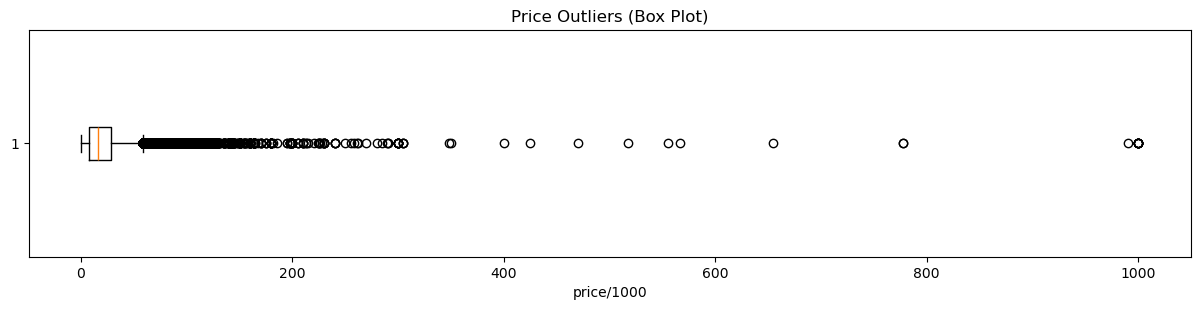

In [15]:
# Visualize price outliers
plt.figure(figsize=(15, 10))
plt.subplot(3, 1, 1)
plt.boxplot(df_car['modified_price'].dropna(), vert=False)
plt.title('Price Outliers (Box Plot)')
plt.xlabel('price/1000')

In [16]:
# The rightward skew of the data distribution may be due to the inclusion of some luxury models in the dataset. 
# We adjusted the IQR coefficients to ensure that we are not removing too much of the correct data.

In [17]:
# Apply IQR with a higher upper limit given the distribution of the variables
Q1_price = df_car['price'].quantile(0.25)
Q3_price = df_car['price'].quantile(0.75)
IQR_price = Q3_price - Q1_price
df_car = df_car[(df_car['price'] >= Q1_price - 1.5 * IQR_price) & (df_car['price'] <= Q1_price + 3 * IQR_price)]
df_car['price'].describe()

count    376787.000000
mean      18634.931033
std       13369.896092
min         500.000000
25%        7500.000000
50%       15590.000000
75%       27590.000000
max       68367.000000
Name: price, dtype: float64

Text(0.5, 0, 'price')

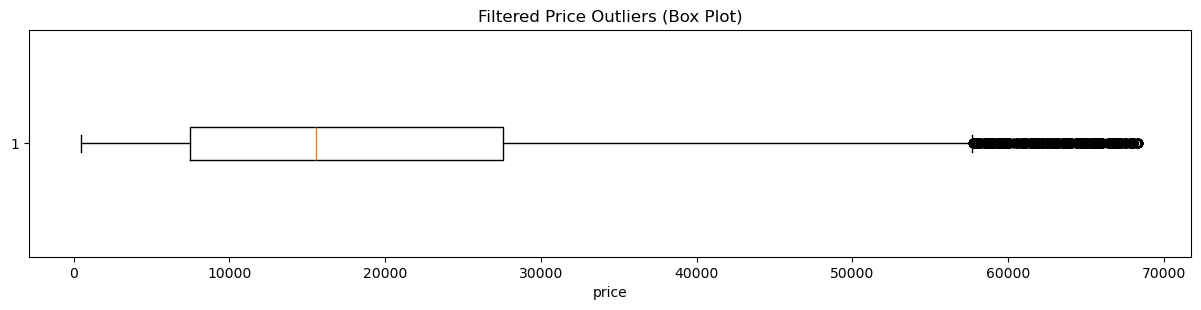

In [18]:
# Visualize price outliers after adjustment
plt.figure(figsize=(15, 10))
plt.subplot(3, 1, 1)
plt.boxplot(df_car['price'].dropna(), vert=False)
plt.title('Filtered Price Outliers (Box Plot)')
plt.xlabel('price')

#### 1.2.2 year

count    375971.000000
mean       2010.918164
std           9.574989
min        1900.000000
25%        2008.000000
50%        2013.000000
75%        2017.000000
max        2022.000000
Name: year, dtype: float64


Text(0.5, 0, 'year')

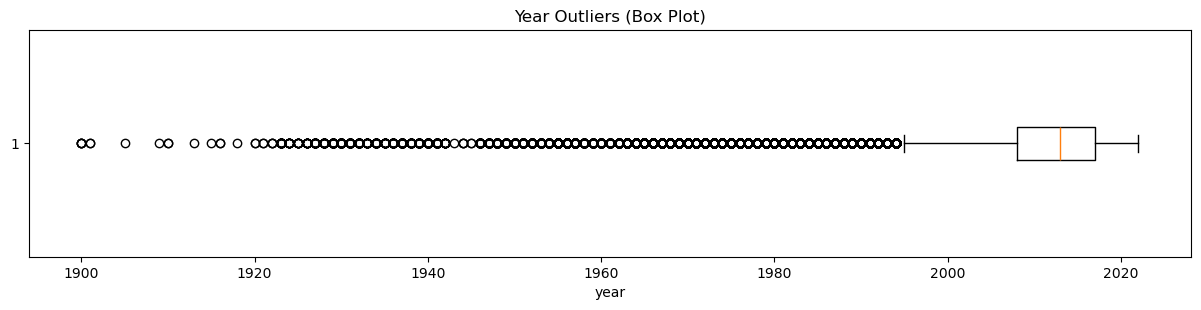

In [19]:
# Remove the missing values (year: 0.28% missing: 1205)
df_car = df_car.dropna(subset=['year'])

print(df_car['year'].describe())
# Visualization of year outliers
plt.figure(figsize=(15, 10))
plt.subplot(3, 1, 2)
plt.boxplot(df_car['year'].dropna(), vert=False)
plt.title('Year Outliers (Box Plot)')
plt.xlabel('year')

In [20]:
sampled_data = df_car.sample(frac=0.01, random_state=42)

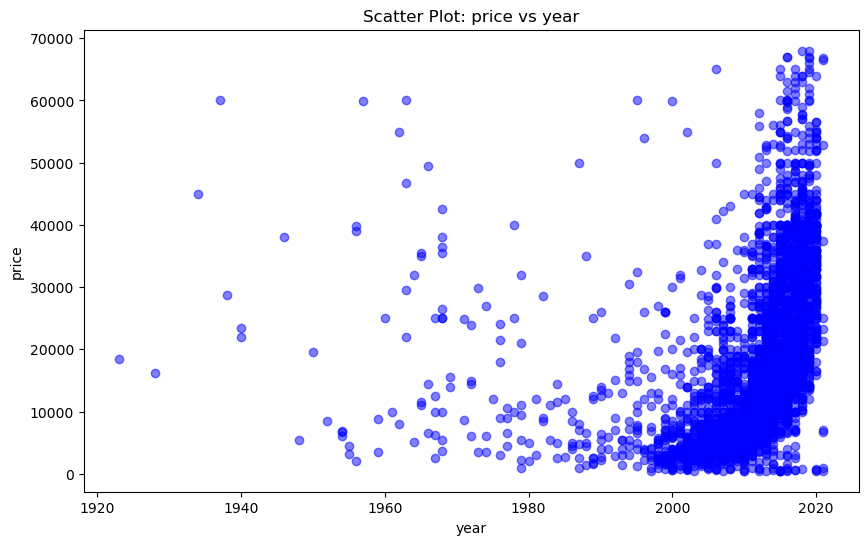

In [21]:
# Create scatter plot of price vs year
plt.figure(figsize=(10, 6))
plt.scatter(sampled_data['year'], sampled_data['price'], alpha=0.5, color='blue')
plt.title('Scatter Plot: price vs year')
plt.xlabel('year')
plt.ylabel('price')
plt.show()

In [22]:
# Remove the outliers shown in the scatter plot
df_car = df_car[df_car['year'] > 1920]

#### 1.2.3 odometer

In [23]:
# Replace missing values with median, considering the percentage of missing values
df_car["odometer"] = df_car["odometer"].fillna(df_car["odometer"].median())

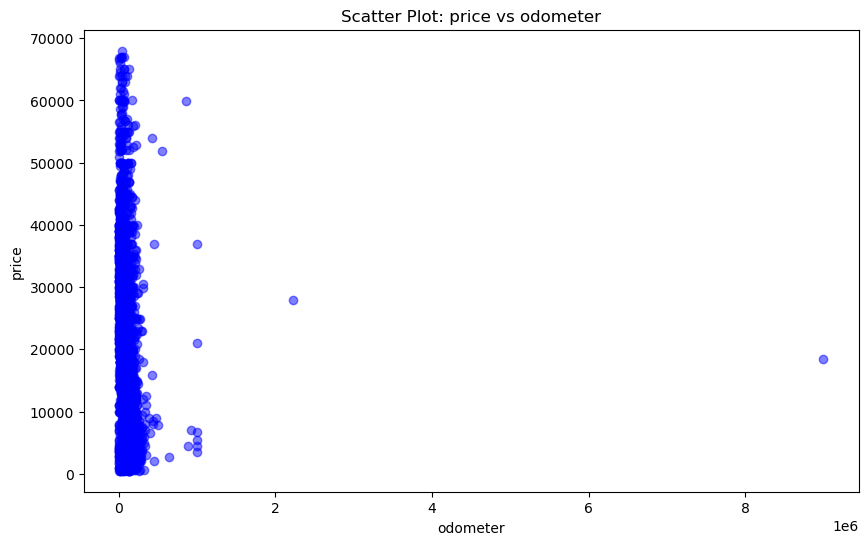

In [24]:
# Create scatter plot of price vs odometer
plt.figure(figsize=(10, 6))
plt.scatter(sampled_data['odometer'], sampled_data['price'], alpha=0.5, color='blue')
plt.title('Scatter Plot: price vs odometer')
plt.xlabel('odometer')
plt.ylabel('price')
plt.show()

count    374181.000000
mean         99.408452
std         192.333025
min           0.000000
25%          39.500000
50%          89.000000
75%         136.965000
max       10000.000000
Name: modified_odometer, dtype: float64


Text(0.5, 0, 'odometer')

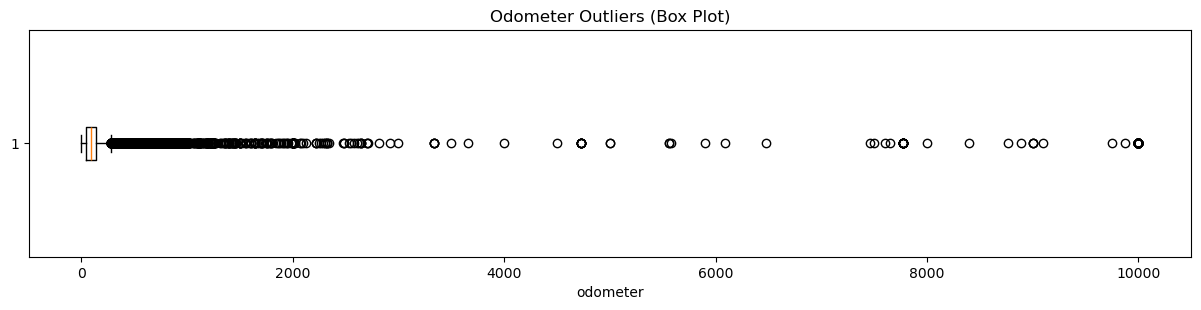

In [25]:
print(df_car['modified_odometer'].describe())

# Visualize odometer outliers
plt.figure(figsize=(15, 10))
plt.subplot(3, 1, 3)
plt.boxplot(df_car['modified_odometer'].dropna(), vert=False)
plt.title('Odometer Outliers (Box Plot)')
plt.xlabel('odometer')


In [26]:
df_car = df_car[(df_car['odometer'] > 100) & (df_car['odometer'] <= 1000000)]
print(df_car['odometer'].describe())

count     371128.000000
mean       96183.711574
std        71481.366624
min          101.000000
25%        40928.000000
50%        89443.000000
75%       137000.000000
max      1000000.000000
Name: odometer, dtype: float64


Text(0.5, 0, 'odometer')

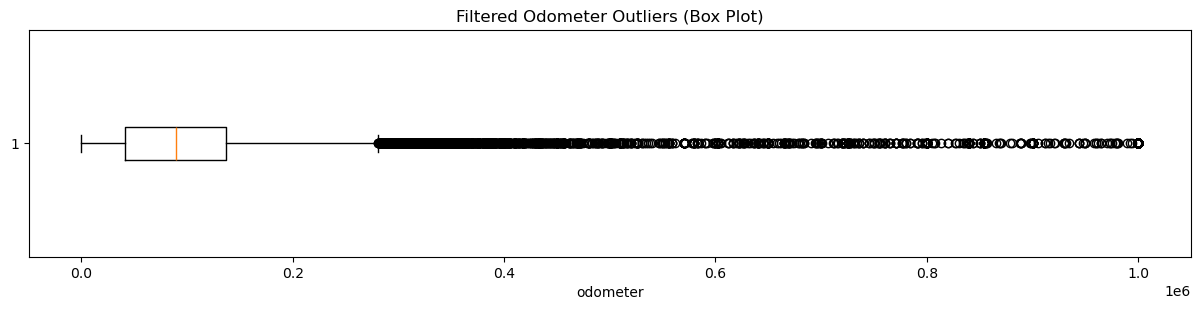

In [27]:
# Visualize odometer outliers after adjustment
plt.figure(figsize=(15, 10))
plt.subplot(3, 1, 1)
plt.boxplot(df_car['odometer'].dropna(), vert=False)
plt.title('Filtered Odometer Outliers (Box Plot)')
plt.xlabel('odometer')

#### 1.2.4 manufacturer

In [28]:
# Define functions
def plot_bar(df, column_name):
    if column_name in df.columns and df[column_name].dtype == 'object':
        plt.figure(figsize=(12, 6))
        df[column_name].value_counts(dropna=False).plot(kind='bar', color='skyblue')
        plt.title(f'Distribution of {column_name}')
        plt.xlabel(column_name)
        plt.ylabel('Count')
        plt.xticks(rotation=90)
        plt.show()
    else:
        print(f"Error: Column '{column_name}' is not an object type or doesn't exist.")

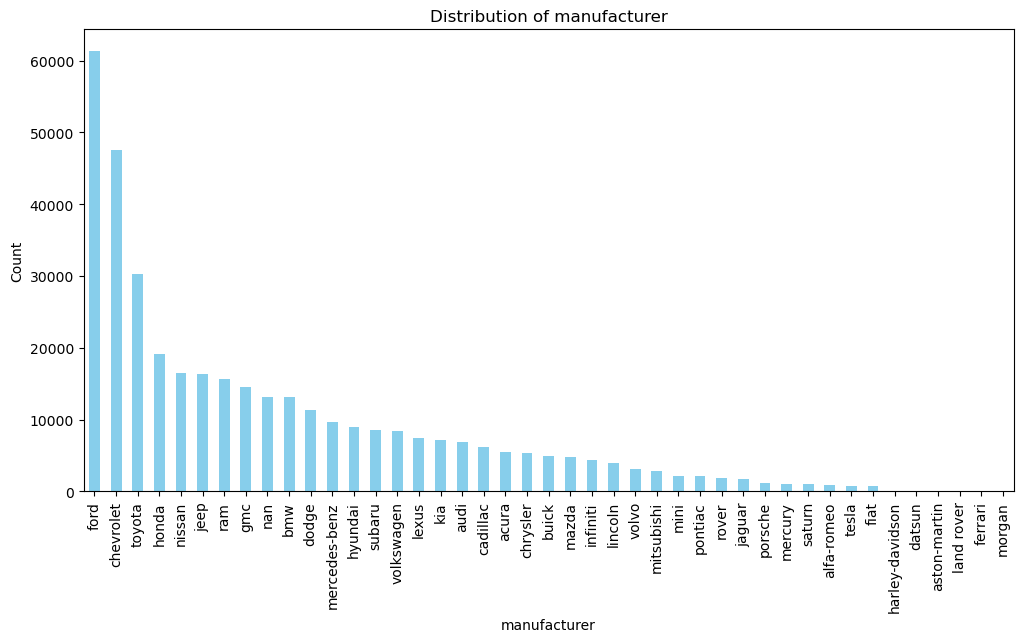

In [29]:
plot_bar(df_car, 'manufacturer')

In [30]:
# From the distribution of the manufacturers, we suggest that using the majority to fill in the missing values is not applicable.
# It is acceptable to drop the missing data, considering again that the percentage of missing values for this variable is less than 5%.
df_car = df_car.dropna(subset=['manufacturer'])

#### 1.2.5 model

In [31]:
# Given that model is a high-cardinality categorical variable, we extract its main classes by regular matching
df_car['model'] = df_car['model'].str.lower().str.strip()

def extract_main_model(text):
    if pd.isna(text):
        return 'unknown'
    match = re.match(r"([a-zA-Z\-0-9]+)", text)
    return match.group(1) if match else 'unknown'

df_car['main_model'] = df_car['model'].apply(extract_main_model)

main_model_counts = df_car['main_model'].value_counts()
print("\nmain_model: ", main_model_counts)


main_model:  main_model
silverado    14479
f-150         8621
1500          8160
sierra        7215
wrangler      6985
             ...  
-350             1
gazelle          1
f260             1
c7h              1
gand             1
Name: count, Length: 2719, dtype: int64


#### 1.2.6 condition

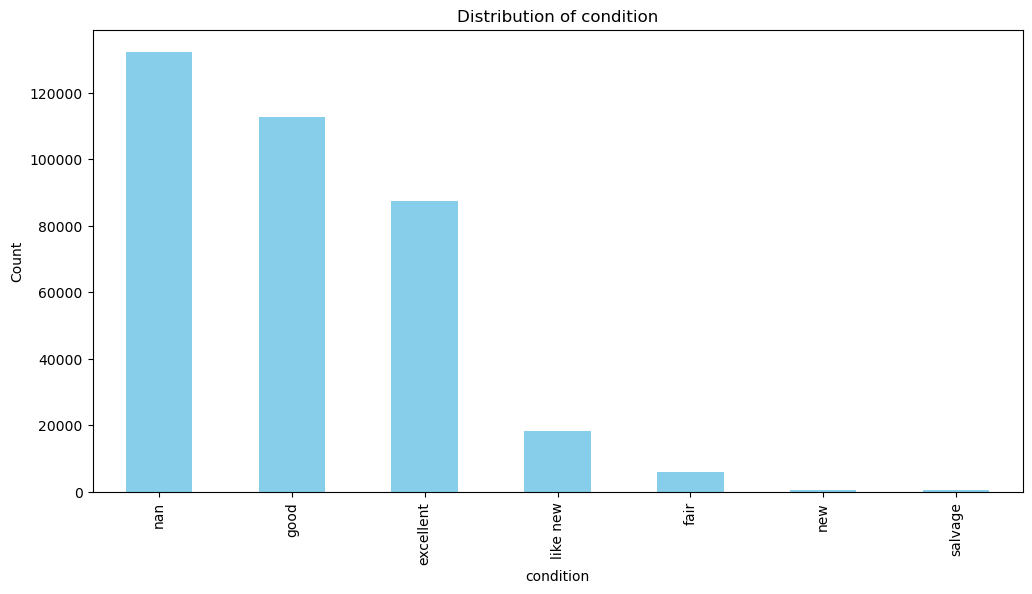

In [32]:
plot_bar(df_car, 'condition')

In [33]:
print(df_car['condition'].unique())

['good' 'excellent' 'fair' nan 'like new' 'new' 'salvage']


In [34]:
# We tried to fill in the missing values of condition using the KNN method.
# Encode condition
condition_mapping = {'new': 5, 'like new': 4, 'excellent': 3, 'good': 2, 'fair': 1, 'salvage': 0}
df_car['condition_encoded'] = df_car['condition'].map(condition_mapping)

# Fill out the features
imputer = KNNImputer(n_neighbors=5)
features = ['year', 'odometer', 'condition_encoded']
df_imputed = df_car[features].copy()

# Conduct KNN filling
imputed_array = imputer.fit_transform(df_imputed)
df_imputed[['year', 'odometer', 'condition_encoded']] = imputed_array

# Map the filled condition back to the original category
inverse_condition_mapping = {v: k for k, v in condition_mapping.items()}
df_car['condition'] = df_imputed['condition_encoded'].round().map(inverse_condition_mapping)

In [35]:
# We also kept a version of the data that directly removed the missing values.
df_car = df_car.dropna(subset=['condition'])

#### 1.2.7 type

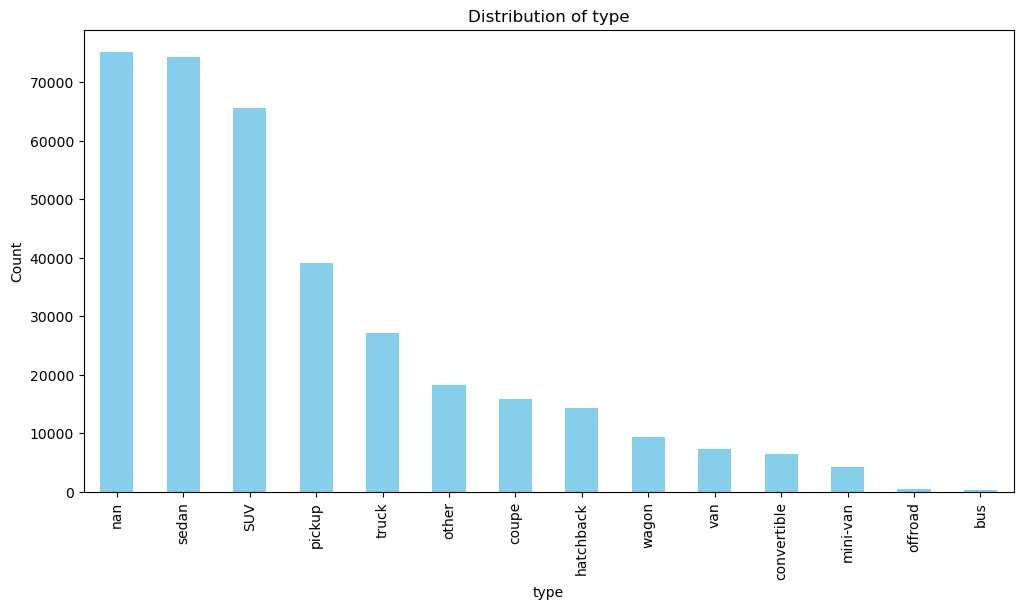

In [36]:
# The percentage of missing values for the type variable is about 20%. 
# Based on the available data, we consider supplementing the missing values of type based on the main_model variable.
plot_bar(df_car, 'type')

In [37]:
crosstab = pd.crosstab(df_car['main_model'], df_car['type'])
print(crosstab)

type        SUV  bus  convertible  coupe  hatchback  mini-van  offroad  other  \
main_model                                                                      
-             3    0            1      3          0         0        0      0   
-150          0    0            0      0          0         0        0      0   
-benz         0    0            0      0          0         0        0      0   
037           0    0            0      1          0         0        0      0   
08            0    0            0      0          0         0        0      0   
...         ...  ...          ...    ...        ...       ...      ...    ...   
zdx           2    0            0      0          0         0        0      0   
zephyr        0    0            0      0          0         0        0      0   
zl1           0    0            0      2          0         0        0      0   
zr2           0    0            0      0          0         0        0      0   
zx2           0    0        

In [38]:
# Fill out the main_type coresponding with one type
single_type_models = crosstab[crosstab.apply(lambda row: (row > 0).sum() == 1, axis=1)].index

for model in single_type_models:
    type_value = crosstab.loc[model].idxmax()  # find the unique type
    df_car.loc[(df_car['main_model'] == model) & (df_car['type'].isna()), 'type'] = type_value

# Fill out the main_type (coresponding with several type) with the most common type
for model in crosstab.index:
    most_common_type = crosstab.loc[model].idxmax()
    df_car.loc[(df_car['main_model'] == model) & (df_car['type'].isna()), 'type'] = most_common_type

# Manually handle special situation
df_car.loc[df_car['main_model'] == 'zdx', 'type'] = 'SUV'
df_car.loc[df_car['main_model'].isin(['zr2', 'zx2']), 'type'] = 'unknown'

In [39]:
# Check the filled results
print(f"missing counts of type: {df_car['type'].isna().sum()}")
print(df_car['type'].value_counts())

missing counts of type: 692
type
sedan          95171
SUV            86034
pickup         56362
truck          30741
coupe          18990
other          18517
hatchback      16626
wagon          10593
van            10065
convertible     7187
mini-van        5960
offroad          620
bus              359
unknown            2
Name: count, dtype: int64


In [40]:
# Drop the values that are still missing
df_car = df_car.dropna(subset=['type'])

#### 1.2.8 cylinders

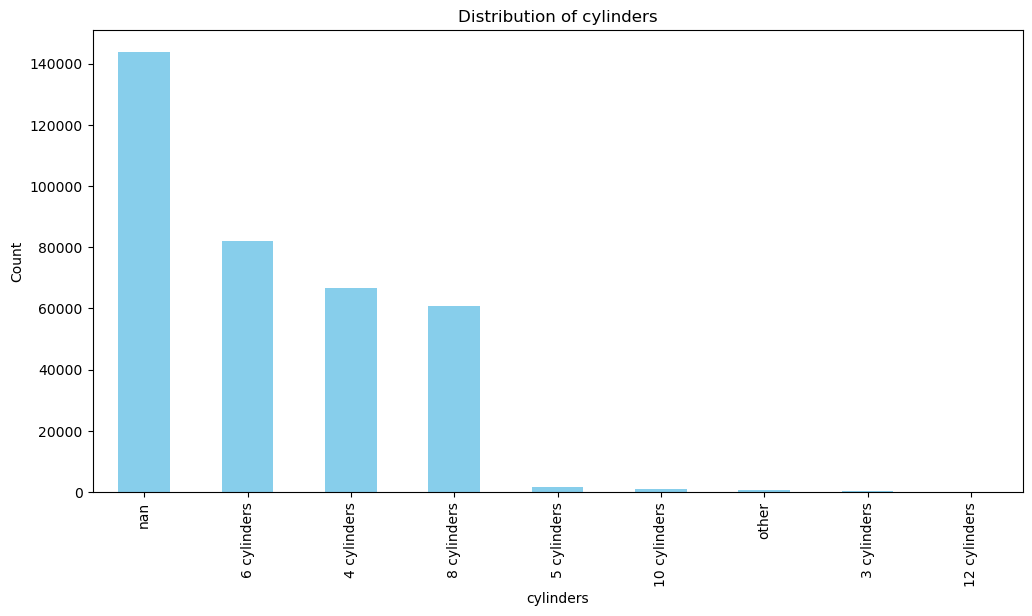

In [41]:
plot_bar(df_car, 'cylinders')

The number of cylinders is generally fixed for different types of vehicles. So we use type to infer the missing values of the cylinders.

In [42]:
# Extract the numeric part of cylinders and converts it to float
df_car['cylinders'] = df_car['cylinders'].str.extract('(\d+)').astype('float')

# Calculate the mode of cylinders for each type
type_cylinders = df_car.groupby('type')['cylinders'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
print(type_cylinders)

type
SUV            6.0
bus            8.0
convertible    8.0
coupe          8.0
hatchback      4.0
mini-van       6.0
offroad        6.0
other          6.0
pickup         8.0
sedan          4.0
truck          8.0
unknown        4.0
van            6.0
wagon          4.0
Name: cylinders, dtype: float64


<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
/var/folders/3f/kqwf1bgd5t5d_6_qr6473jrw0000gn/T/ipykernel_40444/270232548.py:2: SyntaxWarning: invalid escape sequence '\d'
  df_car['cylinders'] = df_car['cylinders'].str.extract('(\d+)').astype('float')


In [43]:
# Map type to cylinders and fill in the missing values.
df_car['cylinders'] = df_car.apply(
    lambda row: type_cylinders[row['type']] if pd.isna(row['cylinders']) else row['cylinders'],
    axis=1
)

df_car['cylinders'] = df_car['cylinders'].astype('int')

print(f"missing counts of cylinders: {df_car['cylinders'].isna().sum()}")
print(df_car['cylinders'].value_counts())

missing counts of cylinders: 0
cylinders
6     129746
4     121258
8     103122
5       1493
10      1064
3        446
12        98
Name: count, dtype: int64


#### 1.2.9 title_status

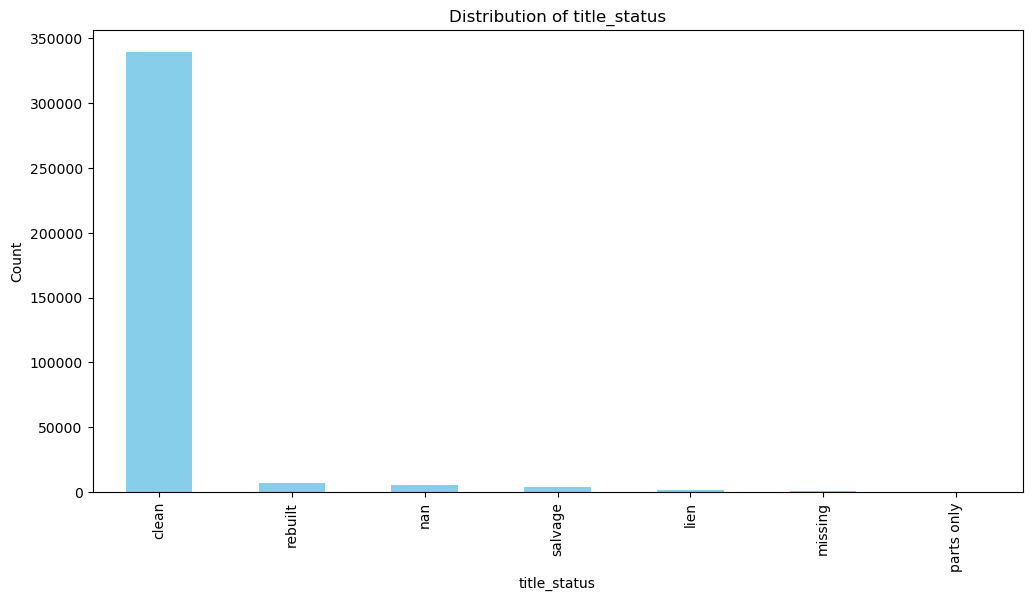

In [44]:
plot_bar(df_car, 'title_status')

In [45]:
# Use clean to fill in the missing values, since title_status has a much higher percentage of clean.
df_car['title_status'].fillna('clean', inplace=True)

print(df_car['title_status'].value_counts())

title_status
clean         345013
rebuilt         6707
salvage         3587
lien            1306
missing          507
parts only       107
Name: count, dtype: int64


/var/folders/3f/kqwf1bgd5t5d_6_qr6473jrw0000gn/T/ipykernel_40444/2888634260.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_car['title_status'].fillna('clean', inplace=True)


#### 1.2.10 drive

In [46]:
drive_counts = df_car['drive'].value_counts()
print("\nmain_drive: ", drive_counts)

# List the most common drives for each type
type_drive_counts = df_car.groupby('type')['drive'].value_counts(normalize=True).unstack().fillna(0)
print(type_drive_counts)


main_drive:  drive
4wd    111160
fwd     90524
rwd     48589
Name: count, dtype: int64
drive             4wd       fwd       rwd
type                                     
SUV          0.704534  0.238738  0.056728
bus          0.042654  0.085308  0.872038
convertible  0.065345  0.211087  0.723568
coupe        0.043917  0.257654  0.698429
hatchback    0.094913  0.858222  0.046865
mini-van     0.043247  0.910123  0.046630
offroad      0.951134  0.019197  0.029668
other        0.350758  0.348232  0.301010
pickup       0.801974  0.045254  0.152772
sedan        0.112008  0.702284  0.185708
truck        0.753852  0.013076  0.233072
unknown      0.500000  0.500000  0.000000
van          0.040485  0.449050  0.510465
wagon        0.497002  0.468983  0.034014


In [47]:
# Build type_drive map based on the results
type_drive_mapping = {
    'SUV': '4wd',
    'bus': 'rwd',
    'convertible': 'rwd',
    'coupe': 'rwd',
    'hatchback': 'fwd',
    'mini-van': 'fwd',
    'offroad': '4wd',
    'other': '4wd',
    'pickup': '4wd',
    'sedan': 'fwd',
    'truck': '4wd',
    'van': 'rwd',
    'wagon': 'fwd'
}
# fill in missing values
df_car['drive'] = df_car.apply(
    lambda row: type_drive_mapping[row['type']] if pd.isna(row['drive']) and row['type'] in type_drive_mapping else row['drive'],
    axis=1
)

In [48]:
drive_counts = df_car['drive'].value_counts()
print("\nmain_drive: ", drive_counts)


main_drive:  drive
4wd    167833
fwd    130810
rwd     58584
Name: count, dtype: int64


#### 1.2.11 paint_color

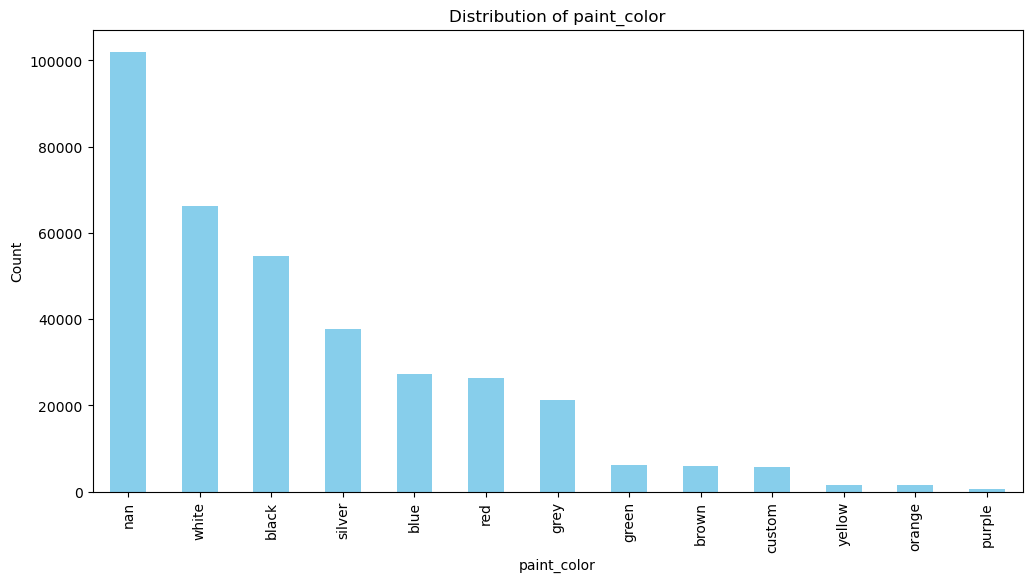

In [49]:
plot_bar(df_car, 'paint_color')

In [50]:
# Fill out the missing values with the most common color from every type of every manufacturer's cars
grouped_color_mode = df_car.groupby(['type', 'manufacturer'])['paint_color'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else 'white')

def fill_paint_color(row):
    if pd.isna(row['paint_color']):
        if (row['type'], row['manufacturer']) in grouped_color_mode.index:
            return grouped_color_mode[(row['type'], row['manufacturer'])]
        else:
            return 'white'  # Default as white
    else:
        return row['paint_color']

df_car['paint_color'] = df_car.apply(fill_paint_color, axis=1)

In [51]:
print(df_car['paint_color'].value_counts())

paint_color
white     109390
black      92254
silver     52606
blue       30785
red        28664
grey       21594
green       6302
brown       6011
custom      5711
orange      1691
yellow      1623
purple       596
Name: count, dtype: int64


### 1.3 Create new variable

In [54]:
# Calculate the vehicle_age
df_car['posting_year'] = df_car['posting_date'].dt.year

df_car['year'] = df_car['year'].fillna(df_car['year'].median())
df_car['posting_year'] = df_car['posting_year'].fillna(df_car['posting_year'].median())

df_car['vehicle_age'] = df_car['posting_year'] - df_car['year']
df_car['vehicle_age'].describe()

count    357227.000000
mean          9.697761
std           8.738204
min          -1.000000
25%           4.000000
50%           8.000000
75%          13.000000
max          99.000000
Name: vehicle_age, dtype: float64

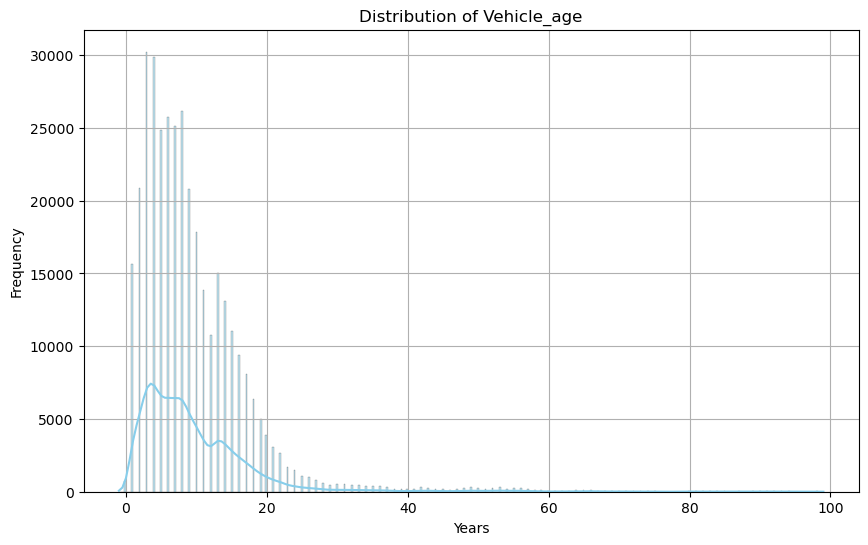

In [55]:
plt.figure(figsize=(10, 6))
sns.histplot(df_car['vehicle_age'], kde=True, color='skyblue')
plt.title("Distribution of Vehicle_age")
plt.xlabel("Years")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [56]:
# Delet unrealistic data in the context of the practical age of vehicles
df_car = df_car[(df_car['vehicle_age'] >= 0) & ((df_car['vehicle_age'] < 25))]

### 1.4 Extract new dataset

In [58]:
# Drop repeatative columns
df_car = df_car.drop(columns=['model','modified_price','modified_odometer','year','posting_date','posting_year','condition_encoded'])

In [59]:
df_car.info()

<class 'pandas.core.frame.DataFrame'>
Index: 343419 entries, 27 to 426879
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   region        343419 non-null  object 
 1   price         343419 non-null  int64  
 2   manufacturer  343419 non-null  object 
 3   condition     343419 non-null  object 
 4   cylinders     343419 non-null  int64  
 5   fuel          343419 non-null  object 
 6   odometer      343419 non-null  float64
 7   title_status  343419 non-null  object 
 8   transmission  343419 non-null  object 
 9   drive         343419 non-null  object 
 10  type          343419 non-null  object 
 11  paint_color   343419 non-null  object 
 12  state         343419 non-null  object 
 13  main_model    343419 non-null  object 
 14  vehicle_age   343419 non-null  float64
dtypes: float64(2), int64(2), object(11)
memory usage: 41.9+ MB


In [60]:
df_car.to_csv('/Users/jane/Desktop/Python and Advanced Data Science/processed_car_data.csv', index=False)

## 2. Explorative Data analysis

Assumptions:
1. Price and Year: negative relation
2. Price and Odometer: negative relation

3. Price and Manufacturer: Premium brands tend to have higher prices.
4. Price and Condition
5. Price and Type
6. Price and Title_status: the new, the higher
7. Price and Fuel Type: Electric vehicles are typically priced higher due to technology and battery costs. Diesel cars are environmental unfriendly and affect the car condition, which can be low in cost.
8. Price and Transmission: Cars with automatic transmission tend to be priced higher than those with manual transmission.
9. Price and Drive: 4wd cars are generally more expensive.
10. Price and Paint_color: whiite is the most common color and other rare colors could be priced higher, though this might be a weaker relationship.

11. Manufacturer and Type
12. Condition and Manufacturer_type
13. Fuel and Type: Specific car types tend to use one kind of fuel.

### 2.1 Correlation Analysis

In [4]:
file_path = '/Users/jane/Desktop/Python and Advanced Data Science/processed_car_data.csv'
df_car = pd.read_csv(file_path)
df_car.head(10)

,region,price,manufacturer,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state,main_model,vehicle_age
0,auburn,33590,gmc,good,8,gas,57923.0,clean,other,4wd,pickup,white,al,sierra,7.0
1,auburn,22590,chevrolet,good,8,gas,71229.0,clean,other,4wd,pickup,blue,al,silverado,11.0
2,auburn,39590,chevrolet,good,8,gas,19160.0,clean,other,4wd,pickup,red,al,silverado,1.0
3,auburn,30990,toyota,good,8,gas,41124.0,clean,other,4wd,pickup,red,al,tundra,4.0
4,auburn,15000,ford,excellent,6,gas,128000.0,clean,automatic,rwd,truck,black,al,f-150,8.0
5,auburn,27990,gmc,good,8,gas,68696.0,clean,other,4wd,pickup,black,al,sierra,9.0
6,auburn,34590,chevrolet,good,6,gas,29499.0,clean,other,4wd,pickup,silver,al,silverado,5.0
7,auburn,35000,toyota,excellent,6,gas,43000.0,clean,automatic,4wd,truck,grey,al,tacoma,2.0
8,auburn,29990,chevrolet,good,6,gas,17302.0,clean,other,4wd,pickup,red,al,colorado,5.0
9,auburn,38590,chevrolet,good,8,gas,30237.0,clean,other,rwd,other,red,al,corvette,10.0


In [5]:
df_car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 343419 entries, 0 to 343418
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   region        343419 non-null  object 
 1   price         343419 non-null  int64  
 2   manufacturer  343419 non-null  object 
 3   condition     343419 non-null  object 
 4   cylinders     343419 non-null  int64  
 5   fuel          343419 non-null  object 
 6   odometer      343419 non-null  float64
 7   title_status  343419 non-null  object 
 8   transmission  343419 non-null  object 
 9   drive         343419 non-null  object 
 10  type          343419 non-null  object 
 11  paint_color   343419 non-null  object 
 12  state         343419 non-null  object 
 13  main_model    343419 non-null  object 
 14  vehicle_age   343419 non-null  float64
dtypes: float64(2), int64(2), object(11)
memory usage: 39.3+ MB


#### 2.1.1 Numerical variables

Correlation with price:
price          1.000000
odometer      -0.539657
vehicle_age   -0.628091
Name: price, dtype: float64


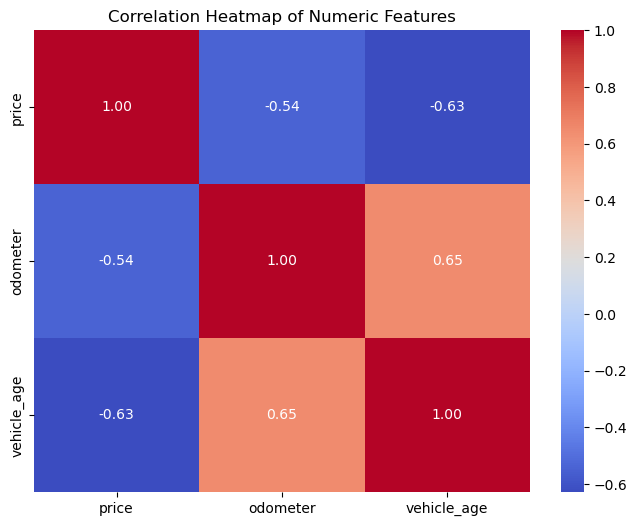

In [9]:
numeric_features = ['price', 'odometer', 'vehicle_age']
correlation_matrix = df_car[numeric_features].corr()

price_corr = correlation_matrix['price'].sort_values(ascending=False)
print("Correlation with price:")
print(price_corr)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

# We observe significant correlation (>0.5) among odometer and price. We decide to include this feature in our model.

#### 2.1.2 Price and Manufacturer

In [10]:
# Manually create a mapping dictionary
brand_tier_map = {
    'gmc': 'low', 'chevrolet': 'low', 'ford': 'low', 'jeep': 'mid', 'nissan': 'low', 'kia': 'low',
    'buick': 'low', 'ram': 'low', 'dodge': 'mid', 'mazda': 'low', 'saturn': 'low', 'pontiac': 'low',
    'chrysler': 'low', 'mercury': 'low', 'mitsubishi': 'low',
    'toyota': 'mid', 'honda': 'mid', 'subaru': 'mid', 'hyundai': 'low', 'volkswagen': 'mid',
    'acura': 'mid', 'volvo': 'high', 'infiniti': 'mid', 'lincoln': 'mid',
    'lexus': 'high', 'bmw': 'high', 'mercedes-benz': 'high', 'audi': 'high', 'porsche': 'high',
    'tesla': 'high', 'jaguar': 'high', 'rover': 'high', 'land rover': 'high', 'ferrari': 'high',
    'aston-martin': 'high'
}

# Map manufacturers to high and low end categories
df_car['brand_tier'] = df_car['manufacturer'].map(brand_tier_map)

                    mean   median
brand_tier                       
high        22413.958075  20999.0
low         19237.989364  15990.0
mid         16728.376612  13999.0


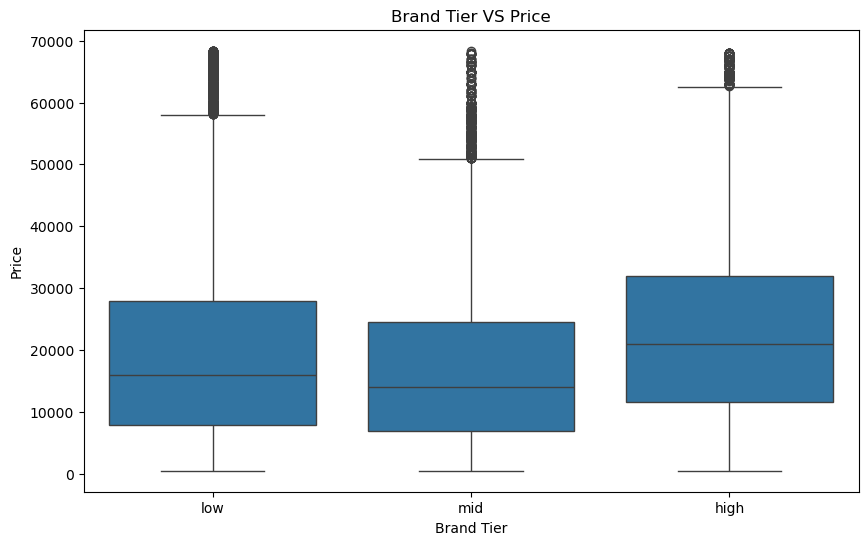

In [11]:
# Calculate and visualize prices by manufacturer category
brand_tier_price = df_car.groupby('brand_tier')['price'].agg(['mean', 'median']).sort_values(by='mean', ascending=False)
print(brand_tier_price)

plt.figure(figsize=(10, 6))
sns.boxplot(x='brand_tier', y='price', data=df_car, order=['low', 'mid', 'high'])
plt.title('Brand Tier VS Price')
plt.xlabel('Brand Tier')
plt.ylabel('Price')
plt.show()

                               count          mean           std    min  \
manufacturer_type_category                                                
high                         19066.0  31451.444718  12895.673747  500.0   
low                         151517.0  12112.348278   8890.190866  500.0   
mid                         172836.0  23480.236658  13471.434321  500.0   

                                25%      50%      75%      max  
manufacturer_type_category                                      
high                        23995.0  32990.0  38990.0  68000.0  
low                          5800.0   9590.0  16590.0  68000.0  
mid                         12900.0  22900.0  32590.0  68367.0  


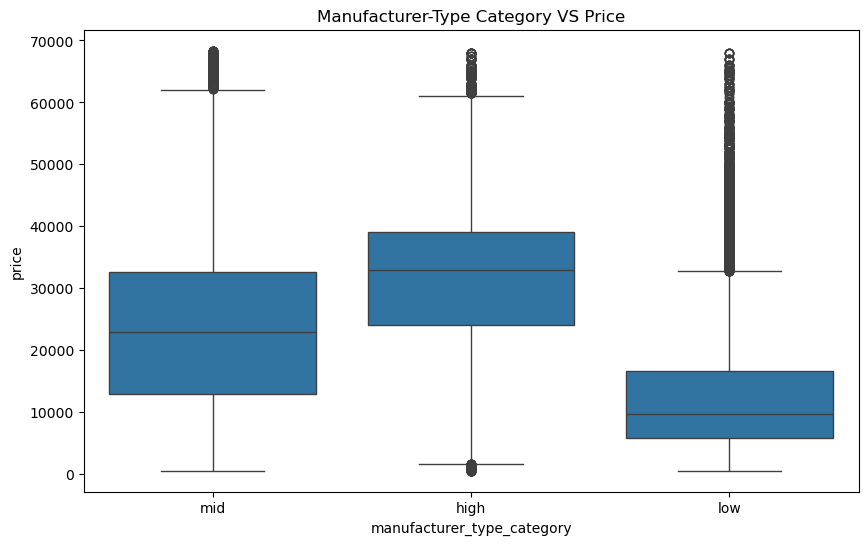

In [12]:
# the results show that there might be other factors
# Create interaction variable
df_car['manufacturer_type'] = df_car['manufacturer'] + '_' + df_car['type']

# Calculate prices by manufacturer_type category
manufacturer_type_price_stats = df_car.groupby('manufacturer_type')['price'].agg(['mean', 'median']).reset_index()
# print(manufacturer_type_price_stats)

# Define the price range
price_bins = [0, 15000, 30000, float('inf')]
price_labels = ['low', 'mid', 'high']

# Add price labels for interaction variable
manufacturer_type_price_stats['price_category'] = pd.cut(
    manufacturer_type_price_stats['median'],
    bins=price_bins,
    labels=price_labels
)

# Map to the original data
price_category_map = manufacturer_type_price_stats.set_index('manufacturer_type')['price_category'].to_dict()
df_car['manufacturer_type_category'] = df_car['manufacturer_type'].map(price_category_map)

# Calculate the statistics of different groups
print(df_car.groupby('manufacturer_type_category')['price'].describe())

# Visualize
plt.figure(figsize=(10, 6))
sns.boxplot(x='manufacturer_type_category', y='price', data=df_car)
plt.title("Manufacturer-Type Category VS Price")
plt.show()


#### 2.1.3 Price and Condition

In [13]:
df_car[['condition', 'price']].groupby(['condition'], as_index=False).mean().sort_values(by='condition', ascending=False)

# the price of good category is extremely high.

,condition,price
5,salvage,4372.414216
4,new,21335.814262
3,like new,19319.608675
2,good,21419.606393
1,fair,3751.872187
0,excellent,16990.494203


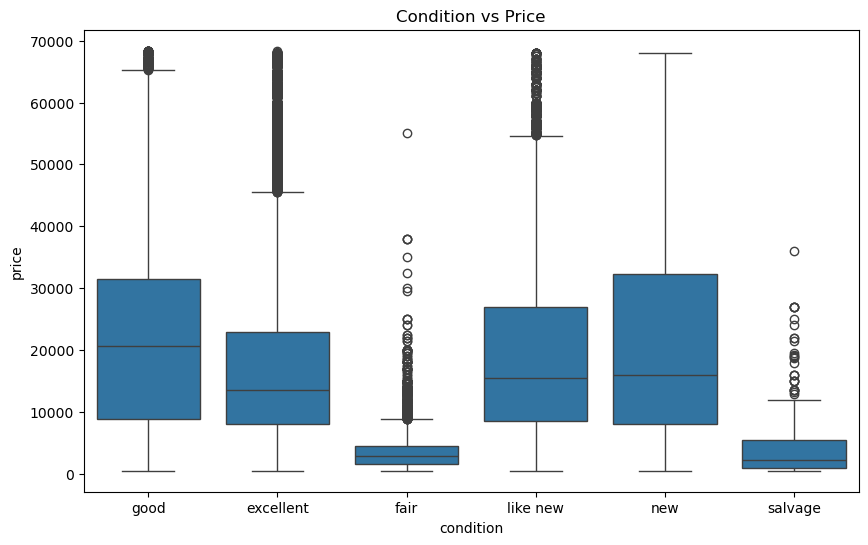

In [14]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_car, x='condition', y='price')
plt.title('Condition vs Price')
plt.show()

In [15]:
# we assume that the abnormal values are caused by the high percentage of high level manufacturers.
# Check the correlation of condition and manufacturer
condition_brand_tier_crosstab = pd.crosstab(df_car['condition'], df_car['manufacturer_type_category'], normalize="index")
print(condition_brand_tier_crosstab)

# it indicates that good condition cars have a higher percentage of high level manufacturers.

manufacturer_type_category      high       low       mid
condition                                               
excellent                   0.034785  0.490344  0.474872
fair                        0.020594  0.550318  0.429087
good                        0.081958  0.375090  0.542952
like new                    0.035890  0.504094  0.460016
new                         0.029851  0.517413  0.452736
salvage                     0.022059  0.620098  0.357843


In [16]:
# Calculate target high category percentage
good_high_ratio = condition_brand_tier_crosstab.loc['good', 'high'] 
print(good_high_ratio)

target_high_ratio = condition_brand_tier_crosstab.drop('good')['high'].mean() 
print(target_high_ratio)

# Count good condition cars
good_count = df_car[df_car['condition'] == 'good'].shape[0]
print(f"Good condition count: {good_count}")

# Calculate target good high category cars
target_high_count = int(good_count * target_high_ratio)
print(target_high_count)

# Filter out data with high and good condition
good_high_cars = df_car[(df_car['manufacturer_type_category'] == 'high') & (df_car['condition'] == 'good')]
sampled_high_cars = good_high_cars.sample(n=target_high_count, random_state=42)

# Merge new good car data
new_good_cars = df_car[(df_car['manufacturer_type_category'] != 'high') & (df_car['condition'] == 'good')]
df_adjusted = pd.concat([sampled_high_cars, new_good_cars])

# Unchange other conditon cars
df_adjusted = pd.concat([df_car[df_car['condition'] != 'good'], df_adjusted])

# Adjusted mean price
mean_price_adjusted_good = df_adjusted[df_adjusted['condition'] == 'good']['price'].mean()
print(f"adjusted mean price of good cars: {mean_price_adjusted_good:.2f}")

0.08195750838650266
0.02863567474979576
Good condition count: 152030
4353
adjusted mean price of good cars: 20779.25


In [17]:
# Extract original data and adjusted data
original_prices = df_car[df_car['condition'] == 'good']['price']
adjusted_prices = df_adjusted[df_adjusted['condition'] == 'good']['price']

# Perform an independent samples t-test
t_stat, p_val = ttest_ind(original_prices, adjusted_prices, equal_var=False)
print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_val:.5f}")

# It indicates that there is significant relation between condition and high level manufacturers. we accept our assumption.

T-statistic: 12.917
P-value: 0.00000


#### 2.1.4 Price and Title_status 

In [18]:
df_car[['title_status', 'price']].groupby(['title_status'], as_index=False).mean().sort_values(by='title_status', ascending=False)

# the price of lien cars is extremely high.

,title_status,price
5,salvage,9691.044560
4,rebuilt,12672.876306
3,parts only,3089.973333
2,missing,3209.716667
1,lien,21481.460094
0,clean,19129.513150


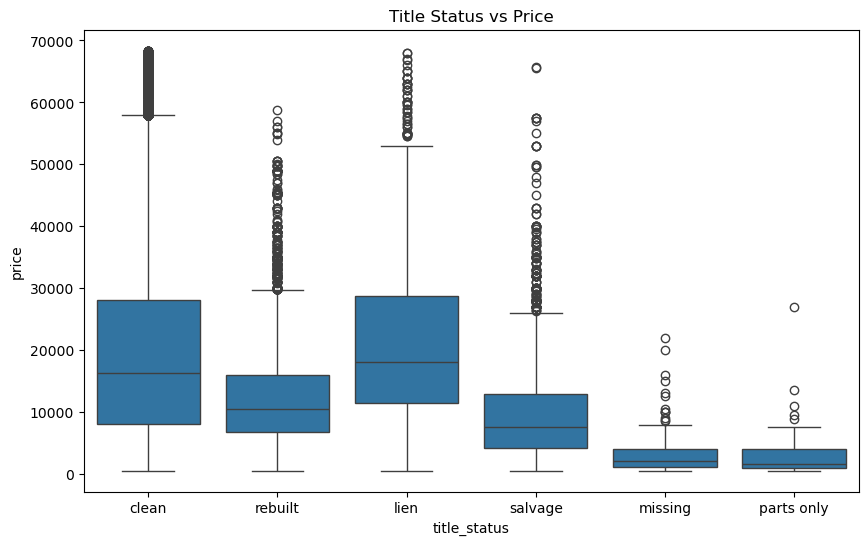

In [19]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_car, x='title_status', y='price')
plt.title('Title Status vs Price')
plt.show()

In [20]:
# we assume that's because the lien cars are new.
lien_cars = df_car[df_car['title_status'] == 'lien']
print(lien_cars['vehicle_age'].describe())

lien_cars_vehicle_age = lien_cars[lien_cars['vehicle_age'] <= 10].shape[0]
print(f"Number of lien cars within 10 years of use: {lien_cars_vehicle_age}")

count    1278.000000
mean        7.580595
std         4.648591
min         0.000000
25%         4.000000
50%         7.000000
75%        10.000000
max        24.000000
Name: vehicle_age, dtype: float64
Number of lien cars within 10 years of use: 987


In [21]:
# we assume that sometimes people have to loan to buy luxury cars.
# Check the relation of lien cars and manufacturers
lien_brand_tier_crosstab = pd.crosstab(df_car['title_status'], df_car['manufacturer_type_category'],normalize='index')
print(lien_brand_tier_crosstab)

# Perform chi-square test

chi2, p, dof, expected = chi2_contingency(lien_brand_tier_crosstab)
print(f"Chi-square value: {chi2:.3f}")
print(f"P-value: {p:.5f}")

# we deny our assumption.

manufacturer_type_category      high       low       mid
title_status                                            
clean                       0.056298  0.436152  0.507551
lien                        0.070423  0.399061  0.530516
missing                     0.005556  0.538889  0.455556
parts only                  0.013333  0.453333  0.533333
rebuilt                     0.028766  0.622104  0.349129
salvage                     0.029803  0.590567  0.379630
Chi-square value: 0.240
P-value: 1.00000


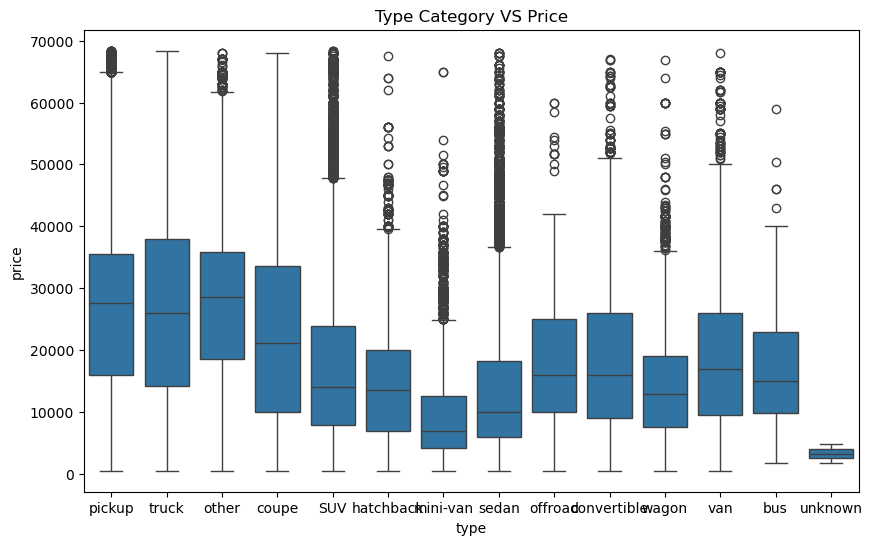

In [22]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='type', y='price', data=df_car)
plt.title("Type Category VS Price")
plt.show()

# some types(pickup, truck, other, coupe) tend to have higher price.

#### 2.1.5 Price and Cylinders

In [23]:
df_car[['cylinders', 'price']].groupby(['cylinders'], as_index=False).mean().sort_values(by='cylinders', ascending=False)

,cylinders,price
6,12,23345.287671
5,10,20938.052531
4,8,25507.302171
3,6,19021.567738
2,5,7598.343378
1,4,13667.934205
0,3,14525.056701


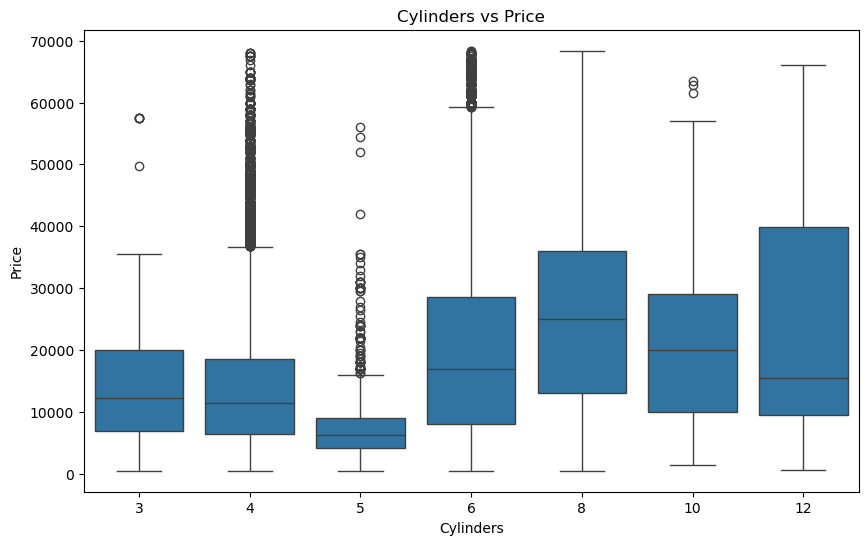

In [24]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='cylinders', y='price', data=df_car)
plt.title("Cylinders vs Price")
plt.xlabel("Cylinders")
plt.ylabel("Price")
plt.show()

#### 2.1.6 Price and Fuel

In [25]:
df_car[['fuel', 'price']].groupby(['fuel'], as_index=False).mean().sort_values(by='fuel', ascending=False)

,fuel,price
4,other,27886.037083
3,hybrid,15721.918832
2,gas,17216.322562
1,electric,25903.327311
0,diesel,32287.030895


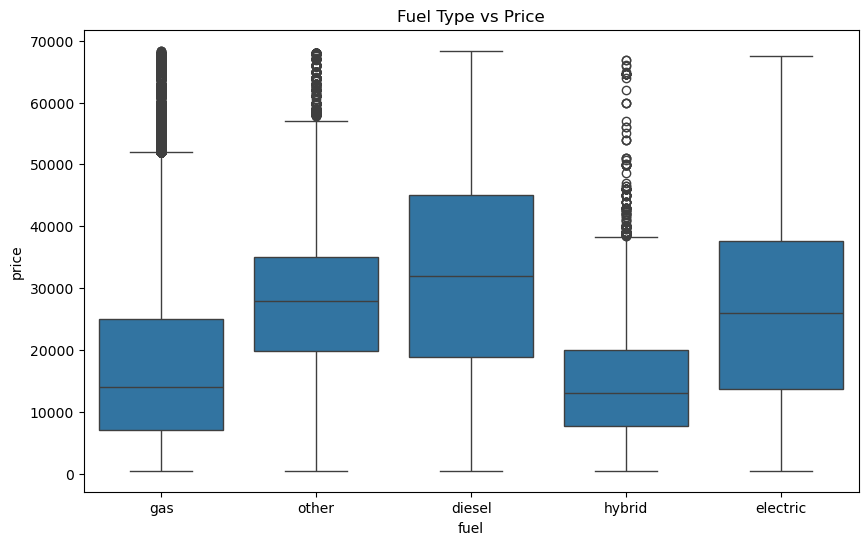

In [26]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_car, x='fuel', y='price')
plt.title('Fuel Type vs Price')
plt.show()

In [27]:
diesel_car_distribution = df_car[df_car['fuel'] == 'diesel']['type'].value_counts()
print(diesel_car_distribution)

# the first two types are also the most expensive type, which illustrates why diesel cars are more expensive than others.

type
pickup         8445
truck          8348
sedan           926
SUV             715
other           634
van             344
wagon           173
hatchback       169
bus              50
coupe            29
convertible      15
mini-van         14
offroad          12
Name: count, dtype: int64


#### 2.1.7 Price and Transmission

In [28]:
df_car[['transmission', 'price']].groupby(['transmission'], as_index=False).mean().sort_values(by='transmission', ascending=False)

,transmission,price
2,other,28594.019164
1,manual,14225.973029
0,automatic,17094.145574


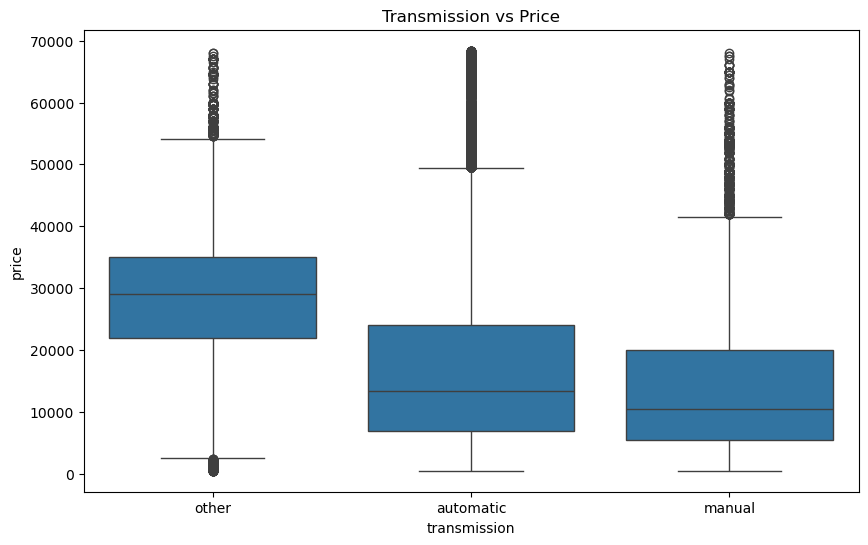

In [29]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_car, x='transmission', y='price')
plt.title('Transmission vs Price')
plt.show()

#### 2.1.8 Price and Drive

In [30]:
df_car[['drive', 'price']].groupby(['drive'], as_index=False).mean().sort_values(by='drive', ascending=False)

,drive,price
2,rwd,20958.096568
1,fwd,13167.539106
0,4wd,22799.626518


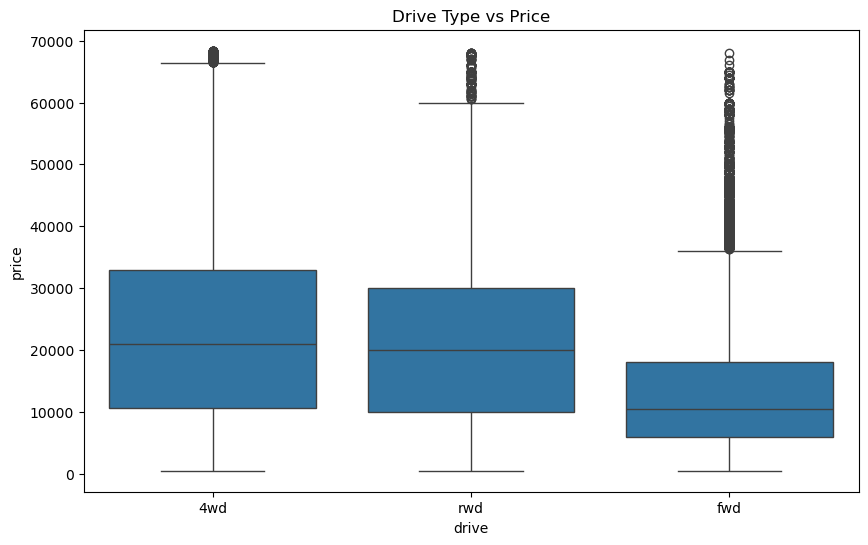

In [31]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_car, x='drive', y='price')
plt.title('Drive Type vs Price')
plt.show()

#### 2.1.9 Price and Paint_color

In [32]:
df_car[['paint_color', 'price']].groupby(['paint_color'], as_index=False).mean().sort_values(by='paint_color', ascending=False)

,paint_color,price
11,yellow,19533.050912
10,white,21782.309872
9,silver,15290.923123
8,red,19502.724287
7,purple,13934.444008
6,orange,18637.395612
5,grey,15102.170619
4,green,13262.564585
3,custom,16231.901195
2,brown,16704.992693


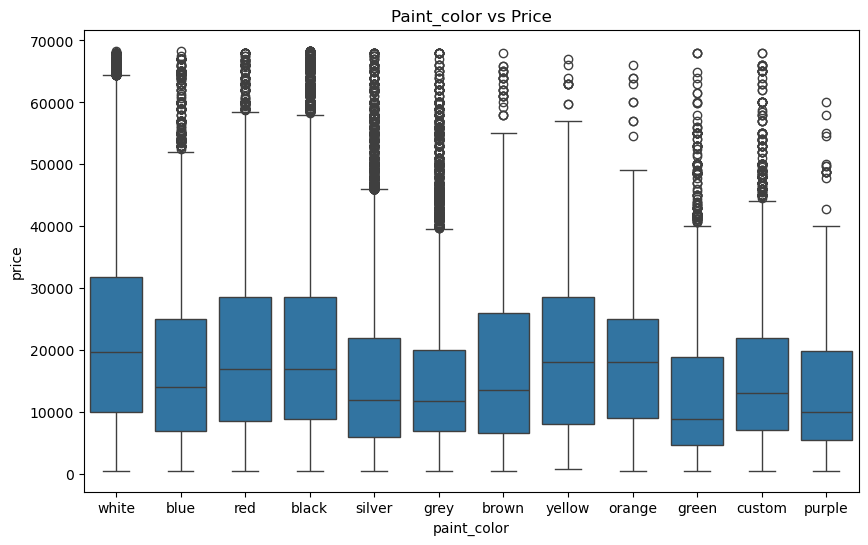

In [33]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_car, x='paint_color', y='price')
plt.title('Paint_color vs Price')
plt.show()

# we notice that the common color cars(white, red, black) show a little higher price.

In [34]:
# Drop extra columns
df_car = df_car.drop(columns=['brand_tier','manufacturer_type_category','manufacturer_type'])

### 2.2 Data Encoding

In [6]:
main_model_counts = df_car['main_model'].value_counts()

# Calculate the cover ratio of top N objects
def get_top_n_percentage(main_model_counts, N):
    return main_model_counts.head(N).sum() / main_model_counts.sum()

for n in [100, 300, 500, 1000]:
    print(f"Top {n} : {get_top_n_percentage(main_model_counts, n):.2%}")

Top 100 : 69.25%
Top 300 : 92.57%
Top 500 : 97.51%
Top 1000 : 99.68%


In [7]:
# Keep top 300 objects and map others as 'Other'
N = 300
top_models = main_model_counts.head(N).index

df_car['main_model'] = df_car['main_model'].apply(lambda x: x if x in top_models else 'Other')

In [8]:
# split the object columns by low and high cardinality
object_cols = [col for col in df_car.columns if df_car[col].dtype == 'object']
low_cardinality_cols = [col for col in object_cols if df_car[col].nunique() <= 15]
high_cardinality_cols = [col for col in object_cols if df_car[col].nunique() > 15]

In [9]:
for col in ['region', 'manufacturer', 'condition', 'fuel', 'title_status','transmission', 'drive', 'type', 'paint_color', 'state', 'main_model']:
    print(f"{col} number of objects: {df_car[col].nunique()}")

region number of objects: 404
manufacturer number of objects: 41
condition number of objects: 6
fuel number of objects: 5
title_status number of objects: 6
transmission number of objects: 3
drive number of objects: 3
type number of objects: 14
paint_color number of objects: 12
state number of objects: 51
main_model number of objects: 301


In [10]:
low_cardinality_cols = ['condition', 'fuel', 'title_status', 'transmission', 'drive', 'type', 'paint_color']
label_encoders = {}

for col in low_cardinality_cols:
    le = LabelEncoder()
    df_car[col] = le.fit_transform(df_car[col].astype(str))  # Encode categorical data as integers
    label_encoders[col] = le  # Store the encoder so you can reverse it if needed

In [11]:
def target_encode(df, target_column, category_column, n_splits=5):
    # Copy the original dataset
    df_encoded = df.copy()

    # Use KFold to group the data
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    df_encoded[category_column + '_encoded'] = np.nan

    for train_index, val_index in kf.split(df_encoded):
        train_fold = df_encoded.iloc[train_index].copy()
        val_fold = df_encoded.iloc[val_index].copy()

        # Calculate the category mean
        mean_encoded = train_fold.groupby(category_column)[target_column].mean()

        # Map to validation set
        df_encoded.loc[val_fold.index, category_column + '_encoded'] = val_fold[category_column].map(mean_encoded)

    # Calculate the mean of all data
    mean_encoded_all = df_encoded.groupby(category_column)[target_column].mean()

    # Encode
    df_encoded[category_column + '_encoded'] = df_encoded[category_column].map(mean_encoded_all).fillna(mean_encoded_all.mean())

    return df_encoded

In [12]:
target_encode_columns = ['region','manufacturer','state','main_model']

df_car = target_encode(df_car, target_column='price', category_column='region')
df_car = target_encode(df_car, target_column='price', category_column='manufacturer')
df_car = target_encode(df_car, target_column='price', category_column='state')
df_car = target_encode(df_car, target_column='price', category_column='main_model')

In [13]:
df_car = df_car.drop(columns=target_encode_columns)

In [14]:
df_car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 343419 entries, 0 to 343418
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   price                 343419 non-null  int64  
 1   condition             343419 non-null  int64  
 2   cylinders             343419 non-null  int64  
 3   fuel                  343419 non-null  int64  
 4   odometer              343419 non-null  float64
 5   title_status          343419 non-null  int64  
 6   transmission          343419 non-null  int64  
 7   drive                 343419 non-null  int64  
 8   type                  343419 non-null  int64  
 9   paint_color           343419 non-null  int64  
 10  vehicle_age           343419 non-null  float64
 11  region_encoded        343419 non-null  float64
 12  manufacturer_encoded  343419 non-null  float64
 13  state_encoded         343419 non-null  float64
 14  main_model_encoded    343419 non-null  float64
dtype

### 2.3 Data Standarization

In [15]:
# Select the feature columns to standardize
standardized_features = ['odometer', 'region_encoded', 'manufacturer_encoded','state_encoded','main_model_encoded']

In [16]:
# Define the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[('num', MinMaxScaler(feature_range=(0, 10)), standardized_features)],
    remainder='passthrough'  # Keep the unconverted columns
)

In [17]:
# Define independent variable and dependent variable
X = df_car.drop(columns=['price'])
y = df_car['price']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

In [19]:
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

In [20]:
new_columns = standardized_features + [col for col in X_train.columns if col not in standardized_features]
new_columns = preprocessor.get_feature_names_out()
print(new_columns)

['num__odometer' 'num__region_encoded' 'num__manufacturer_encoded'
 'num__state_encoded' 'num__main_model_encoded' 'remainder__condition'
 'remainder__cylinders' 'remainder__fuel' 'remainder__title_status'
 'remainder__transmission' 'remainder__drive' 'remainder__type'
 'remainder__paint_color' 'remainder__vehicle_age']


In [21]:
# Convert to DataFrame
X_train_scaled = pd.DataFrame(X_train_scaled, columns=new_columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=new_columns)

In [22]:
print(X_train_scaled.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 274735 entries, 0 to 274734
Data columns (total 14 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   num__odometer              274735 non-null  float64
 1   num__region_encoded        274735 non-null  float64
 2   num__manufacturer_encoded  274735 non-null  float64
 3   num__state_encoded         274735 non-null  float64
 4   num__main_model_encoded    274735 non-null  float64
 5   remainder__condition       274735 non-null  float64
 6   remainder__cylinders       274735 non-null  float64
 7   remainder__fuel            274735 non-null  float64
 8   remainder__title_status    274735 non-null  float64
 9   remainder__transmission    274735 non-null  float64
 10  remainder__drive           274735 non-null  float64
 11  remainder__type            274735 non-null  float64
 12  remainder__paint_color     274735 non-null  float64
 13  remainder__vehicle_age     27

## 3. Ridge Regression

### 3.1 Linear Regression

In [156]:
# Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

LinearRegression()

In [157]:
y_pred = lr_model.predict(X_test_scaled)

In [158]:
# Evaluate the model performance
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"R^2 Score: {r2}")
print(f"Mean Squared Error (MSE): {mse}")

R^2 Score: 0.7124029286123515
Mean Squared Error (MSE): 50273381.2806966


### 3.2 Initial Training

In [159]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

Ridge()

In [160]:
y_pred = ridge_model.predict(X_test_scaled)

In [161]:
# Evaluate the initial model performance
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("R-squared (R2):", r2)
print("Mean Squared Error (MSE):", mse)

R-squared (R2): 0.7124029180914826
Mean Squared Error (MSE): 50273383.11979619


### 3.3 Optimized Training

In [162]:
# Hyperparameter tuning using GridSearchCV
param_grid = {'alpha': [0.01, 0.1, 1, 10, 100, 1000]} # A wide range of alpha values to cover varying levels of regularization
grid_search = GridSearchCV(estimator=Ridge(), param_grid=param_grid, cv=5, scoring='r2')

grid_search.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [0.01, 0.1, 1, 10, 100, 1000]}, scoring='r2')

In [163]:
# Optimal alpha and corresponding R² score
best_alpha = grid_search.best_params_['alpha']
best_r2 = grid_search.best_score_
print("Best Alpha:", best_alpha)
print("Best R² Score:", best_r2)

Best Alpha: 10
Best R² Score: 0.7136521559878917


In [164]:
best_ridge = Ridge(alpha=best_alpha)
best_ridge.fit(X_train_scaled, y_train)

Ridge(alpha=10)

In [165]:
y_pred_best = best_ridge.predict(X_test_scaled)

In [166]:
# Evaluate the optimized model performance
r2_best = r2_score(y_test, y_pred_best)
mse_best = mean_squared_error(y_test, y_pred_best)

print("Optimized Model Performance:")
print("R-squared (R2):", r2_best)
print("Mean Squared Error (MSE):", mse_best)

Optimized Model Performance:
R-squared (R2): 0.7124028227009851
Mean Squared Error (MSE): 50273399.79452389


### 3.4 Model Visualization and Feature Importance

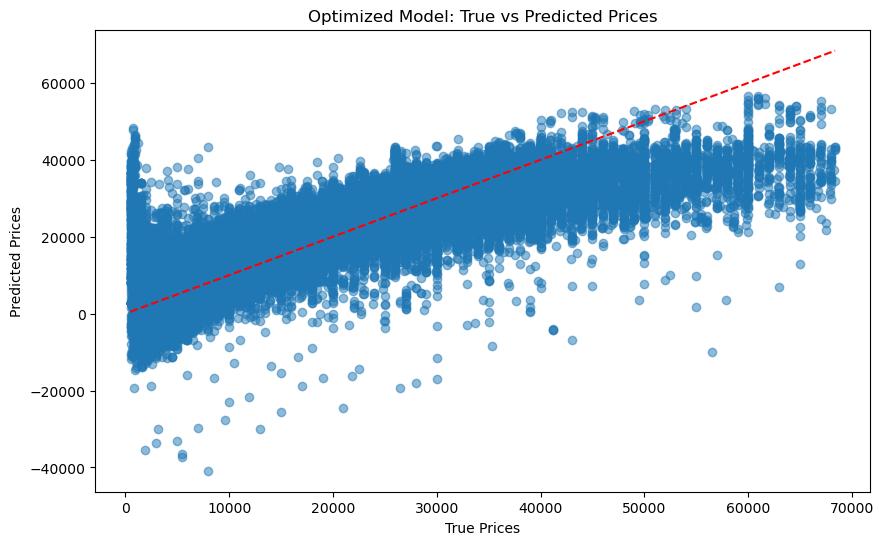

In [167]:
# Visualize initial model performance
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_best, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title("Optimized Model: True vs Predicted Prices")
plt.xlabel("True Prices")
plt.ylabel("Predicted Prices")
plt.show()

Text(0.5, 1.0, 'Feature Importance from Ridge Regression')

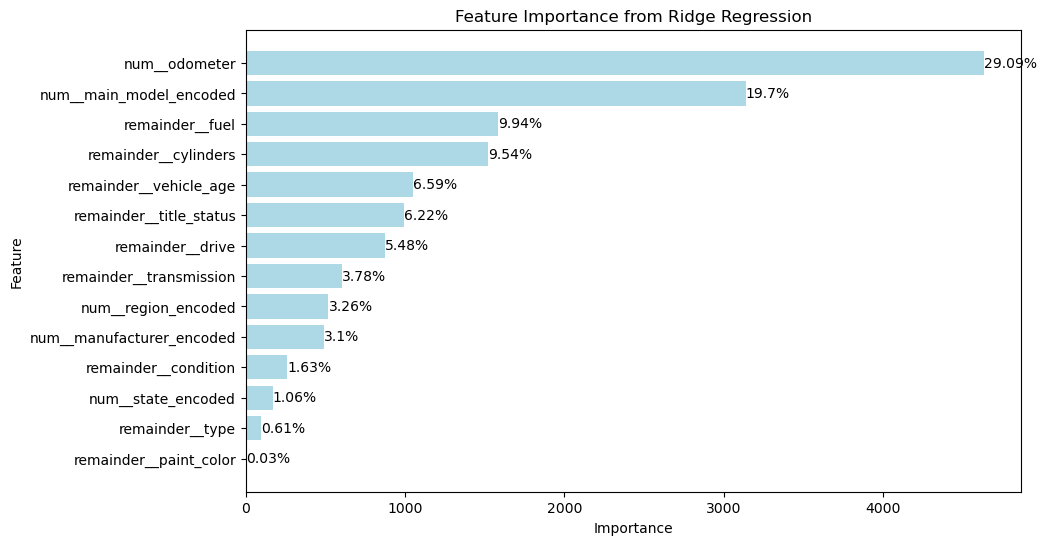

In [168]:
# Get feature importance (coefficients) from the trained Ridge model
feature_importances = np.abs(best_ridge.coef_)

# Retrieve feature names from the preprocessor (ColumnTransformer)
feature_names = X_train_scaled.columns

feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})

# Calculate the importance ratio of each feature
importance_sum = np.sum(feature_importance_df['Importance'])
feature_importance_df['Importance Ratio'] = feature_importance_df['Importance'] / importance_sum
feature_importance_df['Importance Label'] = (feature_importance_df['Importance Ratio'] * 100).round(2)

# Sort by impact ratio
feature_importance_df = feature_importance_df.sort_values(by='Importance Ratio', ascending=True)

# Visaulize
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='lightblue')

# Add text to show the scale
for index, value in enumerate(feature_importance_df['Importance']):
    plt.text(value, index, f'{feature_importance_df["Importance Label"].iloc[index]}%', va='center')

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance from Ridge Regression')

## 4. Decision Tree

### 4.1 Initial Training

In [169]:
# Create a Decision Tree Regression Model
tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_model.fit(X_train_scaled, y_train)

DecisionTreeRegressor(max_depth=5, random_state=42)

In [170]:
y_pred = tree_model.predict(X_test_scaled)

In [171]:
# Evaluate the initial model performance
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("Initial Model Performance:")
print("R-squared (R²):", r2)
print("Mean Squared Error (MSE):", mse)

Initial Model Performance:
R-squared (R²): 0.7175231557165034
Mean Squared Error (MSE): 49378340.42298278


### 4.2 Optimized Training

In [172]:
# Hyperparameter tuning using GridSearchCV
param_grid = {
    'max_depth': [3, 5, 10],
    'min_samples_leaf': [1, 2, 5], # Minimum number of samples for leaf nodes to reduce overfitting
    'min_samples_split': [2, 5, 10], # Make the tree more generalizable
}

# Create a GridSearchCV object and Use 5-fold cross validation
grid_search = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid, cv=5, return_train_score=True)

# Train Grid Search
grid_search.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=42),
             param_grid={'max_depth': [3, 5, 10], 'min_samples_leaf': [1, 2, 5],
                         'min_samples_split': [2, 5, 10]},
             return_train_score=True)

In [173]:
# Output grid search results
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_}")

Best parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best cross-validation score: 0.8183508200047287


In [174]:
# Get the optimal model
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)

In [175]:
r2 = r2_score(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)

print("Optimized Model Performance:")
print("R-squared (R²):", r2)
print("Mean Squared Error (MSE):", mse)

Optimized Model Performance:
R-squared (R²): 0.8182953386412015
Mean Squared Error (MSE): 31762867.670713898


In [176]:
# Cross-Validation Evaluation
# Perform cross-validation on the entire training set
cv_scores = cross_val_score(best_model,X_train_scaled,y_train,cv=5,scoring='r2',n_jobs=-1)

print("Cross-Validation R² Scores:", cv_scores)
print("Mean CV R² Score:", cv_scores.mean())
print("Std Dev of CV R² Score:", cv_scores.std())

Cross-Validation R² Scores: [0.82200085 0.81846669 0.81750463 0.81570036 0.81808157]
Mean CV R² Score: 0.8183508200047287
Std Dev of CV R² Score: 0.0020566776846215216


### 4.3 Model Visualization and Feature Importance

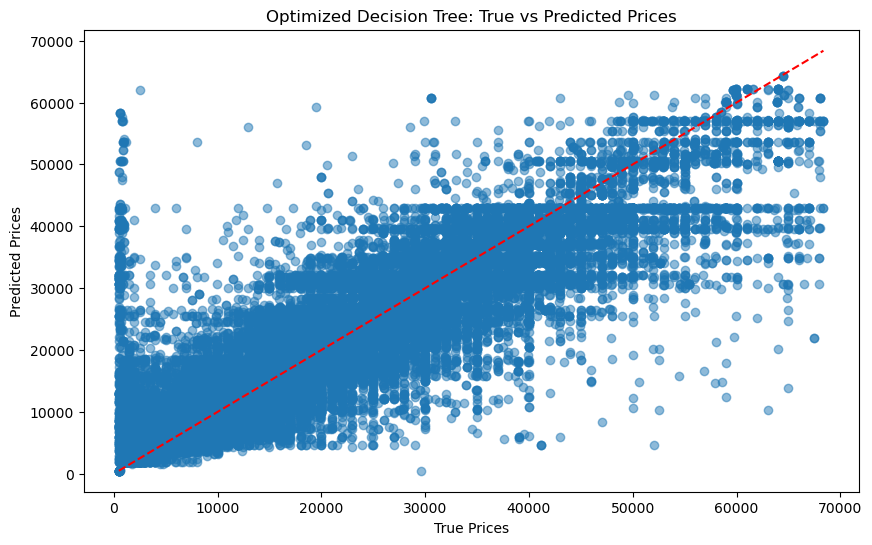

In [177]:
# Visualize true vs predicted prices
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_best, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title("Optimized Decision Tree: True vs Predicted Prices")
plt.xlabel("True Prices")
plt.ylabel("Predicted Prices")
plt.show()

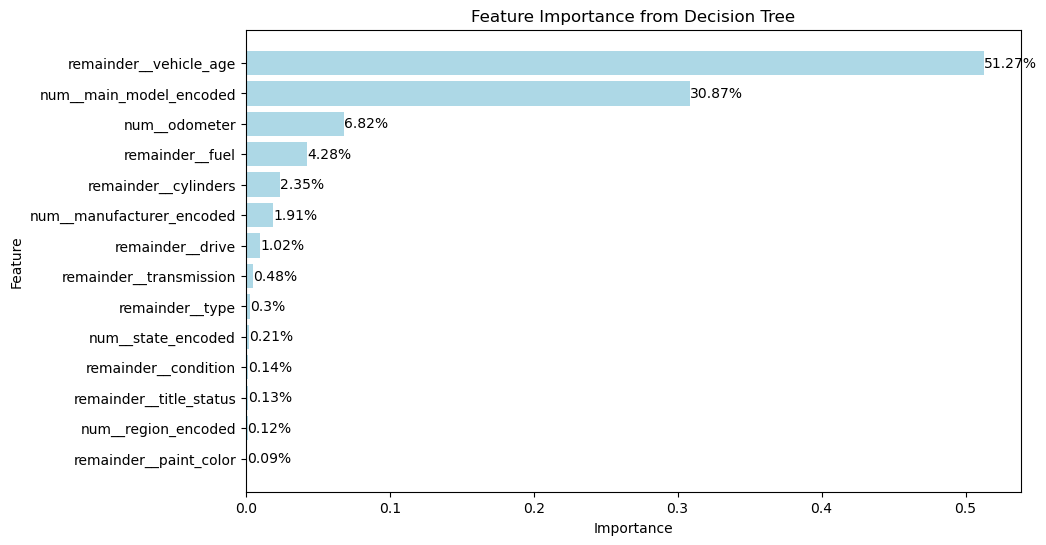

In [178]:
# Get feature importances and their names
feature_importances = best_model.feature_importances_
feature_names = X_train_scaled.columns

feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})

# Calculate the importance ratio of each feature
importance_sum = np.sum(feature_importance_df['Importance'])
feature_importance_df['Importance Ratio'] = feature_importance_df['Importance'] / importance_sum
feature_importance_df['Importance Label'] = (feature_importance_df['Importance Ratio'] * 100).round(2)

# Sort by impact ratio
feature_importance_df = feature_importance_df.sort_values(by='Importance Ratio', ascending=True)

# Visaulize
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='lightblue')

# Add text to show the scale
for index, value in enumerate(feature_importance_df['Importance']):
    plt.text(value, index, f'{feature_importance_df["Importance Label"].iloc[index]}%', va='center')

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance from Decision Tree')
plt.show()

## 5. Random Forest

### 5.1 Initial Training

In [181]:
# Create Random Forest model
rf_model = RandomForestRegressor(max_depth=10,min_samples_leaf=5,random_state=42, n_jobs=-1)

In [182]:
rf_model.fit(X_train_scaled, y_train)

RandomForestRegressor(max_depth=10, min_samples_leaf=5, n_jobs=-1,
                      random_state=42)

In [183]:
y_pred = rf_model.predict(X_test_scaled)

In [184]:
# Evaluate the initial model performance
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("Initial Model Performance:")
print("R-squared (R²):", r2)
print("Mean Squared Error (MSE):", mse)

Initial Model Performance:
R-squared (R²): 0.8371523589180804
Mean Squared Error (MSE): 28466567.86618789


### 5.2 Optimized Model

In [185]:
n_estimators_list = [10, 50, 100, 200, 300]
best_score = -float('inf')
best_n = None

for n in n_estimators_list:
    rf = RandomForestRegressor(n_estimators=n,max_depth=10,min_samples_leaf=5,min_samples_split=2,random_state=42)
    rf.fit(X_train, y_train)
    score = r2_score(y_test, rf.predict(X_test))
    print(f"n_estimators={n}, R²={score:.2f}")
    
    if score > best_score:
        best_score = score
        best_n = n

print(f"Best n_estimators: {best_n}, R²={best_score:.2f}")

n_estimators=10, R²=0.84
n_estimators=50, R²=0.84
n_estimators=100, R²=0.84
n_estimators=200, R²=0.84
n_estimators=300, R²=0.84
Best n_estimators: 200, R²=0.84


In [186]:
adjusted_rf_model=RandomForestRegressor(n_estimators=200,max_depth=None,min_samples_leaf=5,min_samples_split=2,random_state=42)
adjusted_rf_model.fit(X_train_scaled, y_train)

RandomForestRegressor(min_samples_leaf=5, n_estimators=200, random_state=42)

In [187]:
y_pred_best = adjusted_rf_model.predict(X_test_scaled)

In [188]:
# Evaluate the optimized model performance
r2 = r2_score(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)

print("Optimized Model Performance:")
print("R-squared (R²):", r2)
print("Mean Squared Error (MSE):", mse)

Optimized Model Performance:
R-squared (R²): 0.9123331192332299
Mean Squared Error (MSE): 15324601.5378809


In [189]:
# Cross-Validation Evaluation
# Perform cross-validation on the entire training set
cv_scores = cross_val_score(adjusted_rf_model,X_train_scaled,y_train,cv=5,scoring='r2',n_jobs=-1)

print("Cross-Validation R² Scores:", cv_scores)
print("Mean CV R² Score:", cv_scores.mean())
print("Std Dev of CV R² Score:", cv_scores.std())

Cross-Validation R² Scores: [0.90888006 0.90639217 0.90661259 0.90556893 0.90669396]
Mean CV R² Score: 0.9068295430445877
Std Dev of CV R² Score: 0.0011000461237080951


### 5.3 Model Visualization and Feature Importance

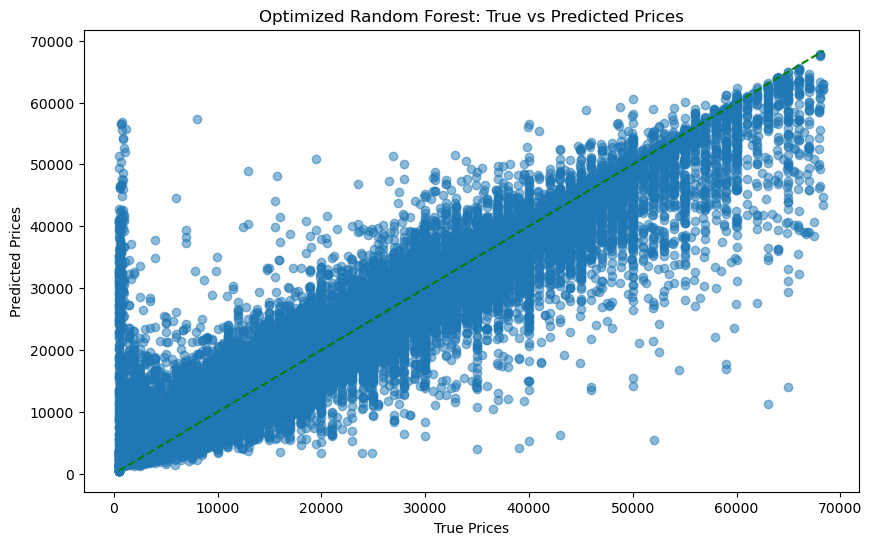

In [190]:
# Visualize true vs predicted prices for the optimized model
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_best, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'g--')
plt.title("Optimized Random Forest: True vs Predicted Prices")
plt.xlabel("True Prices")
plt.ylabel("Predicted Prices")
plt.show()

Text(0.5, 1.0, 'Feature Importance from Random Forest')

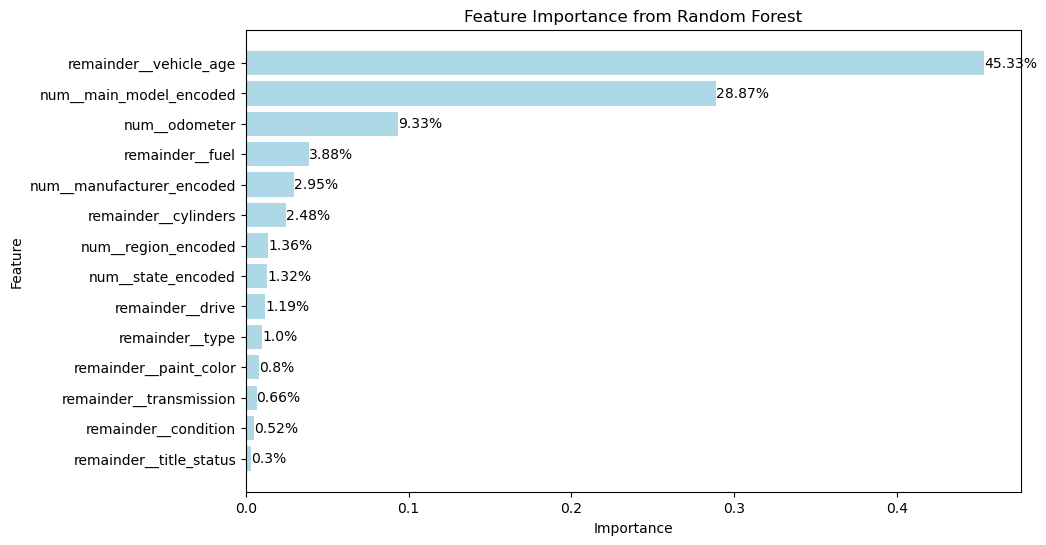

In [191]:
# Get feature importances and their names
feature_importances = adjusted_rf_model.feature_importances_
feature_names = X_train_scaled.columns

feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})

# Calculate the importance ratio of each feature
importance_sum = np.sum(feature_importance_df['Importance'])
feature_importance_df['Importance Ratio'] = feature_importance_df['Importance'] / importance_sum
feature_importance_df['Importance Label'] = (feature_importance_df['Importance Ratio'] * 100).round(2)

# Sort by impact ratio
feature_importance_df = feature_importance_df.sort_values(by='Importance Ratio', ascending=True)

# Visaulize
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='lightblue')

# Add text to show the scale
for index, value in enumerate(feature_importance_df['Importance']):
    plt.text(value, index, f'{feature_importance_df["Importance Label"].iloc[index]}%', va='center')

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance from Random Forest')

## 6. XGBoosts

1. We chose XGBoost because of its outstanding performance in capturing complex nonlinear relationships within the data and high computational efficiency, making it suitable for large dataset. 

2. Additionally, XGBoost includes regularization mechanisms that effectively control model complexity and reduce the risk of overfitting, ensuring stable and reliable predictions for the used car price forecasting task.

### 6.1 Initial Training

In [192]:
# Create a default XGBoost model
xgb_model = XGBRegressor(random_state=42)
xgb_model.fit(X_train_scaled, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=None, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [193]:
y_pred = xgb_model.predict(X_test_scaled)

In [194]:
# Evaluate the initial model performance
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("Initial Model Performance:")
print("R-squared (R²):", r2)
print("Mean Squared Error (MSE):", mse)

Initial Model Performance:
R-squared (R²): 0.8771775960922241
Mean Squared Error (MSE): 21469963.858880516


R² indicates that the model explains 83.71% of the price fluctuations indicating a relatively average performance.

### 6.2 Optimized Model

In [195]:
# Create a Pipeline to combine data preprocessing and model
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(random_state=42))
])

# Define Optuna's objective function for optimizing hyperparameters
def objective(trial):
    # Define hyperparameter space
    param = {
        'model__n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'model__max_depth': trial.suggest_int('max_depth', 3, 7),
        'model__learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 0.2),
        'model__subsample': trial.suggest_uniform('subsample', 0.6, 1.0),
        'model__colsample_bytree': trial.suggest_uniform('colsample_bytree', 0.6, 1.0),
        'model__reg_alpha': trial.suggest_loguniform('reg_alpha', 1e-5, 10.0),
        'model__reg_lambda': trial.suggest_loguniform('reg_lambda', 1e-5, 10.0)
    }
    
    # Set hyperparameters and train the model
    pipeline.set_params(**param)
    pipeline.fit(X_train, y_train)
    
    y_pred = pipeline.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    return r2

# Create an Optuna optimization instance with the goal of maximizing R²
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print("Best Parameters:", study.best_params)
print("Best R²:", study.best_value)

[I 2025-01-20 19:19:34,185] A new study created in memory with name: no-name-a8e3405a-0632-4801-8949-4f7574bc5f28
/var/folders/3f/kqwf1bgd5t5d_6_qr6473jrw0000gn/T/ipykernel_42823/2111762958.py:13: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'model__learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 0.2),
/var/folders/3f/kqwf1bgd5t5d_6_qr6473jrw0000gn/T/ipykernel_42823/2111762958.py:14: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  'model__subsample': trial.suggest_uniform('subsample', 0.6, 1.0),
/var/folders/3f/kqwf1bgd5t5d_6_qr6473jrw0000gn/T/ipykernel_42823/2111762958.py:15: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.

Best Parameters: {'n_estimators': 210, 'max_depth': 7, 'learning_rate': 0.19561355199425975, 'subsample': 0.6954459383015199, 'colsample_bytree': 0.9221929884092898, 'reg_alpha': 0.0002643450690214597, 'reg_lambda': 0.6109891125284548}
Best R²: 0.8972899913787842


In [196]:
best_xgb_model = XGBRegressor(**study.best_params, random_state=42)
best_xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.9221929884092898, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, feature_types=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.19561355199425975, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=7, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=210, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [197]:
y_pred_best = best_xgb_model.predict(X_test)

In [198]:
# Evaluate the optimized model performance
r2 = r2_score(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)

print("Optimized Model Performance:")
print("R-squared (R²):", r2)
print("Mean Squared Error (MSE):", mse)

Optimized Model Performance:
R-squared (R²): 0.8979008197784424
Mean Squared Error (MSE): 17847436.5130347


In [199]:
# Cross-Validation Evaluation
# Perform cross-validation on the entire training set
cv_scores = cross_val_score(best_xgb_model,X_train,y_train,cv=5,scoring='r2',n_jobs=-1)

print("Cross-Validation R² Scores:", cv_scores)
print("Mean CV R² Score:", cv_scores.mean())
print("Std Dev of CV R² Score:", cv_scores.std())

Cross-Validation R² Scores: [0.89785898 0.89351887 0.89559501 0.89452159 0.89598119]
Mean CV R² Score: 0.8954951286315918
Std Dev of CV R² Score: 0.0014620125161417324


### 6.3 Model Visualization and Feature Importance

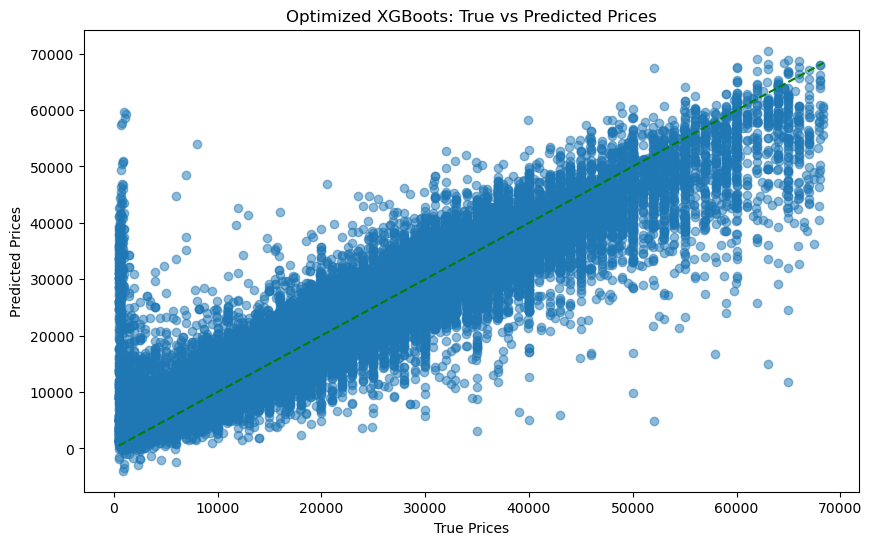

In [200]:
# Visualize true vs predicted prices for the optimized model
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_best, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'g--')
plt.title("Optimized XGBoots: True vs Predicted Prices")
plt.xlabel("True Prices")
plt.ylabel("Predicted Prices")
plt.show()

Text(0.5, 1.0, 'Feature Importance from XGBoots')

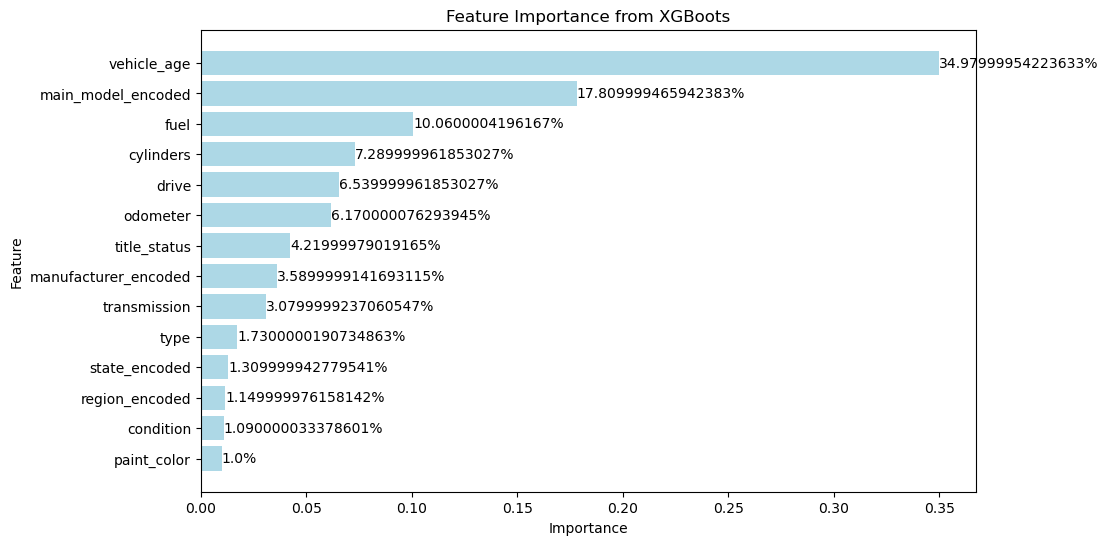

In [202]:
# Get feature importances and their names
feature_importances = best_xgb_model.feature_importances_
feature_names = X_train.columns

feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})

# Calculate the importance ratio of each feature
importance_sum = np.sum(feature_importance_df['Importance'])
feature_importance_df['Importance Ratio'] = feature_importance_df['Importance'] / importance_sum
feature_importance_df['Importance Label'] = (feature_importance_df['Importance Ratio'] * 100).round(2)

# Sort by impact ratio
feature_importance_df = feature_importance_df.sort_values(by='Importance Ratio', ascending=True)

# Visaulize
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='lightblue')

# Add text to show the scale
for index, value in enumerate(feature_importance_df['Importance']):
    plt.text(value, index, f'{feature_importance_df["Importance Label"].iloc[index]}%', va='center')

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance from XGBoots')

## 7. ANN

### 7.1 Initial Training

In [48]:
# Define an ANN function
class KerasRegressorCustom(BaseEstimator, RegressorMixin):
    def __init__(self, learning_rate=0.001, optimizer='adam', neurons=64, activation='relu', epochs=10, batch_size=32):
        self.learning_rate = learning_rate
        self.optimizer = optimizer
        self.neurons = neurons
        self.activation = activation
        self.epochs = epochs
        self.batch_size = batch_size
        self.model = None

    def build_model(self):
        model = Sequential([
            Dense(self.neurons, input_dim=X_train_scaled.shape[1], activation=self.activation),
            Dense(32, activation=self.activation),
            Dense(1, activation='linear')
        ])
        
        if self.optimizer == 'adam':
            model.compile(optimizer=Adam(learning_rate=self.learning_rate), loss='mean_squared_error', metrics=['mse'])
        elif self.optimizer == 'rmsprop':
            model.compile(optimizer=RMSprop(learning_rate=self.learning_rate), loss='mean_squared_error', metrics=['mse'])
        
        return model

    def fit(self, X, y):
        self.model = self.build_model()
        self.model.fit(X, y, epochs=self.epochs, batch_size=self.batch_size, verbose=0)
        return self

    def predict(self, X):
        return self.model.predict(X, verbose=0)

    def score(self, X, y):
        y_pred = self.predict(X)
        return -mean_squared_error(y, y_pred)  # Negative MSE for scoring, as sklearn expects higher values to be better

In [49]:
# Create a ANN model
ann_model = KerasRegressorCustom()
ann_model.fit(X_train_scaled, y_train)


/Applications/anaconda3/envs/jingyu/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


KerasRegressorCustom()

In [50]:
y_pred=ann_model.predict(X_test_scaled)

In [51]:
# Evaluate the initial model performance
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("Initial Model Performance:")
print("R-squared (R²):", r2)
print("Mean Squared Error (MSE):", mse)

Initial Model Performance:
R-squared (R²): 0.7832068780684368
Mean Squared Error (MSE): 37896502.99744362


### 7.2 Optimized Model

In [52]:
# RandomizedSearchCV
# Define the hyperparameters space to search
param_dist = {
    'batch_size': [32, 64],
    'epochs': [50, 100],
    'optimizer': ['adam', 'rmsprop'],
    'neurons': [64, 128, 256],
    'activation': ['relu', 'tanh', 'sigmoid'],
    'learning_rate': uniform(0.0001, 0.01),  
}


# Create a RandomizedSearchCV instance
random_search = RandomizedSearchCV(
    estimator=ann_model,                        # Pass a callable function to create the model
    param_distributions=param_dist,             # The parameter space to search
    n_iter=10,                                  # Number of random combinations to try
    cv=3,                                       # Cross-validation folds
    scoring='neg_mean_squared_error',           # Custom scoring function (MSE)
    verbose=2,                                  # Verbose output
    n_jobs=-1,                                  # Use all CPU cores
    random_state=42                             # Random seed for reproducibility
)

# Fit the RandomizedSearchCV to the data
random_search.fit(X_train_scaled, y_train)

# Output the best parameters and the best MSE score
print("Best Parameters:", random_search.best_params_)
print("Best MSE:", random_search.best_score_)


Fitting 3 folds for each of 10 candidates, totalling 30 fits


/Applications/anaconda3/envs/jingyu/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Applications/anaconda3/envs/jingyu/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Applications/anaconda3/envs/jingyu/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  su

[CV] END activation=sigmoid, batch_size=64, epochs=50, learning_rate=0.001934347898661638, neurons=64, optimizer=adam; total time= 2.3min


/Applications/anaconda3/envs/jingyu/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


[CV] END activation=sigmoid, batch_size=64, epochs=50, learning_rate=0.001934347898661638, neurons=64, optimizer=adam; total time= 2.3min


/Applications/anaconda3/envs/jingyu/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (37 outputs left out)

/Applications/anaconda3/envs/jingyu/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


[CV] END activation=sigmoid, batch_size=64, epochs=100, learning_rate=0.004767628932479799, neurons=64, optimizer=adam; total time= 5.1min
[CV] END activation=sigmoid, batch_size=32, epochs=50, learning_rate=0.0007505159298527952, neurons=64, optimizer=rmsprop; total time= 4.7min
[CV] END activation=sigmoid, batch_size=64, epochs=100, learning_rate=0.004767628932479799, neurons=64, optimizer=adam; total time= 5.0min
[CV] END activation=sigmoid, batch_size=32, epochs=50, learning_rate=0.0007505159298527952, neurons=64, optimizer=rmsprop; total time= 4.3min
[CV] END activation=sigmoid, batch_size=32, epochs=50, learning_rate=0.0007505159298527952, neurons=64, optimizer=rmsprop; total time= 4.1min
[CV] END activation=tanh, batch_size=64, epochs=100, learning_rate=0.0031461376917337066, neurons=64, optimizer=rmsprop; total time= 3.5min
[CV] END activation=tanh, batch_size=64, epochs=100, learning_rate=0.0031461376917337066, neurons=64, optimizer=rmsprop; total time= 3.0min
[CV] END activat

/Applications/anaconda3/envs/jingyu/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Best Parameters: {'activation': 'relu', 'batch_size': 64, 'epochs': 100, 'learning_rate': 0.007180725777960455, 'neurons': 128, 'optimizer': 'adam'}
Best MSE: -30031887.777053118


In [71]:
# Predict with the best model
best_ann_model = random_search.best_estimator_
best_ann_model.fit(X_train_scaled, y_train)

y_pred_best = best_ann_model.predict(X_test_scaled)

/Applications/anaconda3/envs/jingyu/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [57]:
# Evaluate the optimized model performance
r2 = r2_score(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)

print("Optimized Model Performance:")
print("R-squared (R²):", r2)
print("Mean Squared Error (MSE):", mse)

Optimized Model Performance:
R-squared (R²): 0.8333493227696585
Mean Squared Error (MSE): 29131357.27239217


### 7.3 Model Visualization and Feature Importance

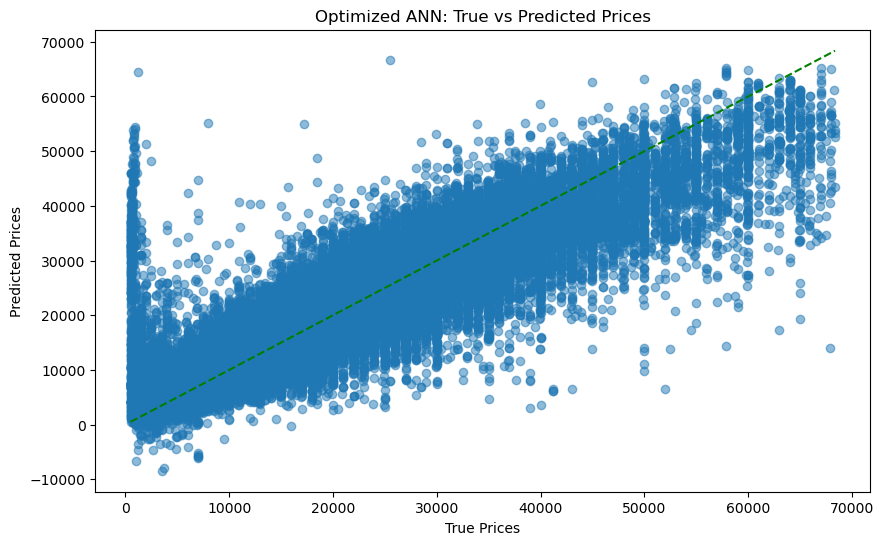

In [58]:
# Visualize true vs predicted prices for the optimized model
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_best, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'g--')
plt.title("Optimized ANN: True vs Predicted Prices")
plt.xlabel("True Prices")
plt.ylabel("Predicted Prices")
plt.show()

In [83]:
from sklearn.inspection import permutation_importance

result = permutation_importance(best_ann_model, X_test_scaled, y_test, n_repeats=10, random_state=42)

Text(0.5, 1.0, 'Feature Importance from ANN')

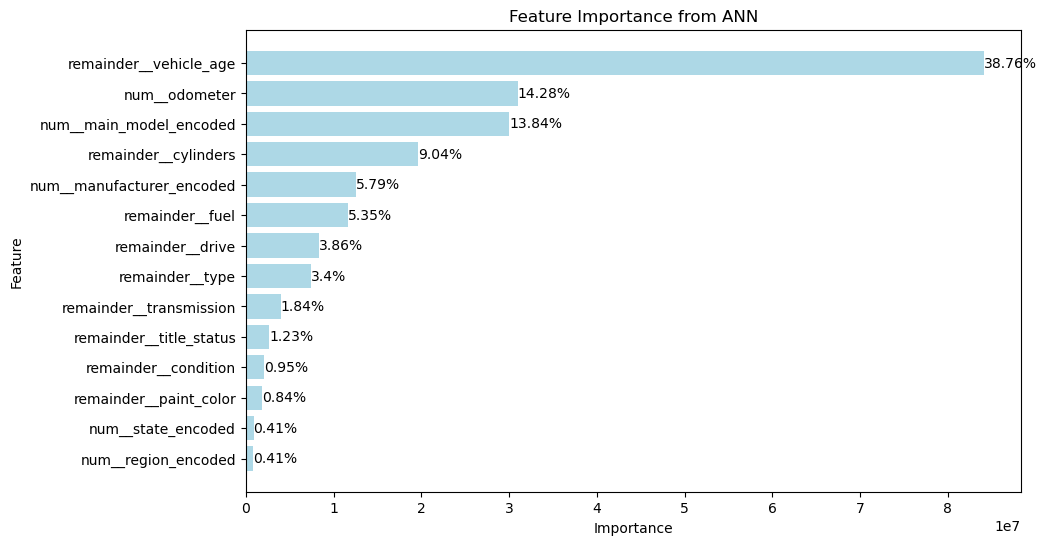

In [82]:
# Get feature importances and their names
feature_importances = result.importances_mean 
feature_names = X_train_scaled.columns

feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})

# Calculate the importance ratio of each feature
importance_sum = np.sum(feature_importance_df['Importance'])
feature_importance_df['Importance Ratio'] = feature_importance_df['Importance'] / importance_sum
feature_importance_df['Importance Label'] = (feature_importance_df['Importance Ratio'] * 100).round(2)

# Sort by impact ratio
feature_importance_df = feature_importance_df.sort_values(by='Importance Ratio', ascending=True)

# Visaulize
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='lightblue')

# Add text to show the scale
for index, value in enumerate(feature_importance_df['Importance']):
    plt.text(value, index, f'{feature_importance_df["Importance Label"].iloc[index]}%', va='center')

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance from ANN')